In [ ]:
# ==============================================================================
# Purpose:
#   CD4 T pipeline mirroring the DC block:
#     (1) run CNA neighborhood association for race (NHB vs NHW) in CD4 T cells
#         within each CD4 subset x disease state,
#     (2) correlate per-cell race_coef with gene expression (fast Spearman),
#     (3) run preranked GSEA (Hallmark + ImmPort) on rho,
#     (4) make Figure 7 panels:
#           - UMAP colored by CD4 subsets, race, and significant race_coef
#           - selected pathway NES mini-panels + per-state bubble plots (ImmPort)
#           - checkpoint gene expression: per-cell (Scanpy) and pseudobulk (pb table),
#             with Mann–Whitney annotations.
#
# Steps:
#   A) Setup plotting, load meta, load AnnData.
#   B) Map covariates (age/race/group/diabetes/obesity/race-stage) into dat.obs;
#      encode diabetes/obesity as 0/1; encode group & race as numeric for CNA.
#   C) Subset CD4 T (predicted.celltype.l1 == 'CD4 T'); load UMAP coords; neighbors.
#   D) Build sample-level covariate table; add batch; run CNA race association; save pkl.
#   E) For each CD4 subtype x disease state: CNA, Spearman,
#      prerank GSEA; save CSVs; repeat per disease state for all CD4T.
#   F) Load overall CD4T CNA object; generate UMAP figure panels.
#   G) Aggregate GSEA outputs; plot selected pathway NES bars (single + multi-panel).
#   H) Bubble plots per disease state (ImmPort; NES vs pathway; size=Tag%).
#   I) Checkpoint genes (PDCD1/CTLA4/LAG3/HAVCR2/PVR):
#       - per-cell: seaborn box+strip across race-stage within each CD4 subset
#       - pseudobulk: long-format pb matrix; per-group (HRL/DCIS/BC) box+strip across race.
# ==============================================================================

# Header

In [1]:
from utils import *

In [2]:
import sys
sys.path.insert(0, '/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src')
import cna

In [3]:
import gseapy as gp
import scanpy as sc
from itertools import product
from matplotlib.patches import Patch
from textwrap import fill

In [4]:
os.chdir('../')

In [5]:
sc.settings.set_figure_params(dpi=600, dpi_save=600)  # 600 dpi for publication
sc.settings.figdir = "plots/Figure1"

rcParams.update({
    'font.family': 'Arial',
    'svg.fonttype': 'none',    # Keep SVG text as font
    'font.size': 6,            # Main font size (5–7pt recommended)
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,
    'legend.fontsize': 6,
    'legend.title_fontsize': 6,
    'figure.dpi': 600,

    # --- Nature Immunology-style axes/ticks ---
    'axes.linewidth': 0.5,          # Axis lines: 0.5 pt
    'xtick.major.width': 0.5,        # Major tick lines
    'ytick.major.width': 0.5,
    'xtick.minor.width': 0.5,
    'ytick.minor.width': 0.5,
    'lines.linewidth': 0.7,          # Plot/data lines
    'axes.grid': False,              # No grid lines

    # --- Ticks on all sides ---
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.top': False,
    'xtick.bottom': False,
    'ytick.left': True,
    'ytick.right': False,


    # --- Tick label padding (minimal) ---
    'xtick.major.pad': 0,
    'ytick.major.pad': 0,

    # ---- Thin lines for Nature Immunology style ----
    'lines.linewidth': 0.5,     # General line width (default: 1.5)
    'patch.linewidth': 0.5,     # Outline for violin/bars (default: 1.0)
    
})

# plt.rcParams['axes.grid'] = False      # Extra guarantee, if using seaborn
# sns.set_style("white")                 # Removes upper/right axes and grid

# -- Scanpy vector-friendly mode --
sc.settings._vector_friendly = True

In [6]:
cells_group = {
    'B':['Naive B',
 'Mature B',
 'Memory B',
 'Plasmablast'],
    'T':['Naive CD4T',
 'Central Memory CD4T',
 'Effector Memory CD4T',
 'Cytotoxic CD4T',
 'Treg',
 'Naive CD8T',
 'Central Memory CD8T',
 'Effector Memory CD8T',
 'Double Negative T',
 'γδ T',
 'MAIT'],
    'DC':[
   'cDC1',
 'cDC2',
 'pDC'     
    ],
    'Mono':[
        'Classical Monocyte',
 'Intermediate Monocyte',
 'Nonclassical Monocyte',
 'Cytotoxic Monocyte'
        ],
    'NK':[
        'CD56-dim NK',
 'CD56-bright NK',
 'Proliferating NK'
    ]
}

In [7]:
import numpy as np
import pandas as pd
from scipy.stats import rankdata
from scipy import sparse
from scipy.stats import t as student_t
from statsmodels.stats.multitest import multipletests

def fast_spearman_ann(adata, obs_key, genes=None, chunk_size=2000, eps=1e-12):
    """
    Fast Spearman correlation between a per-cell variable (obs_key)
    and expression of each gene in adata.
    Returns a DataFrame with columns: rho, pval, fdr.
    """
    if genes is None:
        genes = adata.var_names
    X = adata[:, genes].X
    n_cells, n_genes = X.shape

    # rank-transform the covariate
    c = pd.to_numeric(adata.obs[obs_key], errors='coerce').to_numpy()
    r_c = rankdata(c, method='average')
    r_c0 = r_c - r_c.mean()
    norm_rc0 = np.linalg.norm(r_c0) + eps

    rho = np.empty(n_genes, dtype=float)

    for start in range(0, n_genes, chunk_size):
        end = min(start + chunk_size, n_genes)
        Xi = X[:, start:end]

        if sparse.issparse(Xi):
            Xi = Xi.toarray()

        # rank each gene (column) across cells
        R = np.apply_along_axis(rankdata, 0, Xi, method='average')
        R0 = R - R.mean(axis=0, keepdims=True)
        denomX = np.linalg.norm(R0, axis=0) + eps

        # Pearson on ranks = Spearman
        rho[start:end] = (R0.T @ r_c0) / (norm_rc0 * denomX)

    # --- p-values (two-sided) via t-approximation ---
    df = n_cells - 2
    # Clamp |rho| to < 1 to avoid division by zero
    rho_clamped = np.clip(rho, -1 + 1e-15, 1 - 1e-15)
    t_stat = rho_clamped * np.sqrt(df / (1 - rho_clamped**2))
    pval = 2 * student_t.sf(np.abs(t_stat), df=df)

    # --- FDR (Benjamini–Hochberg) ---
    fdr = multipletests(pval, method='fdr_bh')[1]

    out = pd.DataFrame(
        {'rho': rho, 'pval': pval, 'fdr': fdr},
        index=pd.Index(genes, name='gene')
    )
    out.name = f'spearman_{obs_key}'
    return out

In [8]:
with open('data/Legends/celltypelevel3_palette.pkl','rb') as f:
    palette_all = pkl.load(f)

palette_all

{'Naive B': (0.843137, 0.0, 0.0),
 'Mature B': (0.54902, 0.235294, 1.0),
 'Memory B': (0.007843, 0.533333, 0.0),
 'Plasmablast': (0.0, 0.67451, 0.780392),
 'Naive CD4T': (0.596078, 1.0, 0.0),
 'Central Memory CD4T': (1.0, 0.498039, 0.819608),
 'Effector Memory CD4T': (0.423529, 0.0, 0.309804),
 'Cytotoxic CD4T': (1.0, 0.647059, 0.188235),
 'Treg': (0.345098, 0.231373, 0.0),
 'Naive CD8T': (0.0, 0.341176, 0.34902),
 'Central Memory CD8T': (0.0, 0.0, 0.866667),
 'Effector Memory CD8T': (0.0, 0.992157, 0.811765),
 'Double Negative T': (0.631373, 0.458824, 0.415686),
 'γδ T': (0.737255, 0.717647, 1.0),
 'MAIT': (0.584314, 0.709804, 0.470588),
 'cDC1': (0.752941, 0.015686, 0.72549),
 'cDC2': (0.392157, 0.329412, 0.454902),
 'pDC': (0.47451, 0.0, 0.0),
 'Classical Monocyte': (0.027451, 0.454902, 0.847059),
 'Intermediate Monocyte': (0.996078, 0.960784, 0.564706),
 'Nonclassical Monocyte': (0.0, 0.294118, 0.0),
 'Cytotoxic Monocyte': (0.560784, 0.478431, 0.0),
 'CD56-dim NK': (1.0, 0.447059, 

# Load data

In [9]:
meta = pd.read_csv('data/01_meta/meta_pt.csv', index_col=0)
#meta.index = [x.replace('_','-') for x in meta.index]

meta['race-stage'] = meta['race'].astype(str) + '-' + meta['group'].astype(str)
meta = meta.drop(columns = ['race_stage'])

meta['race-stage'] = pd.Categorical(
    meta['race-stage'],
    categories=['NHW-HRL', 'NHW-DCIS', 'NHW-BC','NHB-HRL', 'NHB-DCIS', 'NHB-BC'],
    ordered=True
    )

meta

,dataset_name,batch,viability_pct,group,race,age,diabetes,obesity,race-stage
sampleid,,,,,,,,,
9-D,Pool137_7,1,95,DCIS,NHW,37.0,N,Y,NHW-DCIS
30-D,Pool137_12,1,92,DCIS,NHW,78.0,N,N,NHW-DCIS
36-D,Pool137_18,1,93,DCIS,NHB,39.0,N,Y,NHB-DCIS
119-D,Pool137_20,1,95,DCIS,NHB,80.0,N,Y,NHB-DCIS
28-D,Pool137_24,1,94,DCIS,NHW,53.0,N,N,NHW-DCIS
53-D,Pool137_27,1,96,DCIS,NHB,45.0,N,N,NHB-DCIS
77-D,Pool137_30,1,90,DCIS,NHW,45.0,N,N,NHW-DCIS
31-D,Pool138_6,2,93,DCIS,NHW,44.0,N,N,NHW-DCIS
6-H,Pool137_6,1,94,HRL,NHW,71.1,N,Y,NHW-HRL


In [10]:
dat = sc.read_h5ad(
    'data/03_cleandata/ft_all.h5ad'
)

dat.obs

,nFeaturess_RNA,nFeaturess_RNA_by_counts,total_counts,total_counts_mt,pct_counts_mt,doublets_score,nCount_RNA,nFeature_RNA,percent.mt,predicted.celltype.l1.score,...,predicted.celltype.l3,mapping.score,RNA_snn_res.0.8,seurat_clusters,dataset_name,RNA_snn_res.0.1,S.Score,G2M.Score,Phase,celltype_level3
Pool137_10_AAACCTGAGACTCGGA-1,1095.0,1095,2669.0,80.0,2.997377,0.039230,2669.0,1095.0,2.997377,0.987477,...,CD4 TCM_1,0.827455,0,0,Pool137_10,0,-0.035611,-0.030749,G1,Naive CD4T
Pool137_10_AAACCTGAGATCTGCT-1,2474.0,2472,6188.0,178.0,2.876535,0.021953,6188.0,2472.0,2.876535,1.000000,...,CD16 Mono,0.740965,5,5,Pool137_10,5,0.004613,0.004461,S,Nonclassical Monocyte
Pool137_10_AAACCTGAGATTACCC-1,1436.0,1436,3504.0,100.0,2.853881,0.039230,3504.0,1436.0,2.853881,0.996618,...,CD8 Naive,0.874696,6,6,Pool137_10,6,0.027257,-0.066766,S,Naive CD8T
Pool137_10_AAACCTGAGCTGCGAA-1,1033.0,1033,2685.0,104.0,3.873371,0.053408,2685.0,1033.0,3.873371,0.990250,...,CD4 TCM_1,0.842401,0,0,Pool137_10,0,-0.049705,0.004598,G2M,Naive CD4T
Pool137_10_AAACCTGAGGACACCA-1,2518.0,2515,6370.0,189.0,2.967033,0.012493,6370.0,2515.0,2.967033,1.000000,...,CD16 Mono,0.836383,5,5,Pool137_10,5,0.003770,-0.014496,S,Nonclassical Monocyte
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Pool138_9_TTTGTCATCCATGAAC-1,1309.0,1308,2604.0,43.0,1.651306,0.026204,2604.0,1308.0,1.651306,1.000000,...,CD14 Mono,0.925401,2,1,Pool138_9,1,0.128049,0.014490,S,Classical Monocyte
Pool138_9_TTTGTCATCCTAGGGC-1,1464.0,1464,3533.0,41.0,1.160487,0.105614,3533.0,1464.0,1.160487,1.000000,...,CD4 TCM_3,0.890462,5,0,Pool138_9,0,0.020027,-0.014519,S,Effector Memory CD4T
Pool138_9_TTTGTCATCGCACTCT-1,1310.0,1310,3125.0,56.0,1.792000,0.020296,3125.0,1310.0,1.792000,1.000000,...,CD4 TCM_1,0.842334,1,0,Pool138_9,0,-0.052514,-0.009035,G1,Naive CD4T
Pool138_9_TTTGTCATCTAACTGG-1,1774.0,1774,5072.0,107.0,2.109622,0.085158,5072.0,1774.0,2.109621,1.000000,...,CD4 TCM_1,0.824522,1,0,Pool138_9,0,-0.042068,0.002366,G2M,Naive CD4T


In [11]:
for col in ['age', 'race-stage', 'race', 'group', 'diabetes', 'obesity']:
    dat.obs[col] = dat.obs['dataset_name'].map(meta.set_index('dataset_name')[col])
    
for xcol in ['diabetes','obesity']:
    dat.obs[xcol] = [1 if x=='Y' else 0 for x in dat.obs[xcol]]

xcol = 'group'
dat.obs[xcol] = [0 if x=='HRL' else 1 if x=='DCIS' else 2 for x in dat.obs[xcol]]

xcol = 'race'
dat.obs[xcol] = [0 if x=='NHW' else 1 if x=='NHB' else None for x in dat.obs[xcol]]

dat.obs.columns

Index(['nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts',
       'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA',
       'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score',
       'predicted.celltype.l1', 'predicted.celltype.l2.score',
       'predicted.celltype.l2', 'predicted.celltype.l3.score',
       'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8',
       'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score',
       'G2M.Score', 'Phase', 'celltype_level3', 'age', 'race-stage', 'race',
       'group', 'diabetes', 'obesity'],
      dtype='object')

In [12]:
celltype_major = 'CD4 T'

In [13]:
d = dat[
    dat.obs['predicted.celltype.l1'] == celltype_major
]
d

View of AnnData object with n_obs × n_vars = 167053 × 27879
    obs: 'nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score', 'predicted.celltype.l1', 'predicted.celltype.l2.score', 'predicted.celltype.l2', 'predicted.celltype.l3.score', 'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8', 'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score', 'G2M.Score', 'Phase', 'celltype_level3', 'age', 'race-stage', 'race', 'group', 'diabetes', 'obesity'
    var: 'vf_vst_counts.Pool137_10_mean', 'vf_vst_counts.Pool137_10_variance', 'vf_vst_counts.Pool137_10_variance.expected', 'vf_vst_counts.Pool137_10_variance.standardized', 'vf_vst_counts.Pool137_10_variable', 'vf_vst_counts.Pool137_10_rank', 'vf_vst_counts.Pool137_11_mean', 'vf_vst_counts.Pool137_11_variance', 'vf_vst_counts.Pool137_11_variance.expected', 'vf_vst_counts.Pool137_11_variance.stand

In [14]:
umap = pd.read_csv(f"data/03_cleandata/ft_{celltype_major}_UmapCoords.csv",
                   index_col=2
                  ).loc[d.obs.index,:]

d.obsm['X_umap'] = umap.values

/tmp/ipykernel_3383482/3805644948.py:5: ImplicitModificationWarning: Setting element `.obsm['X_umap']` of view, initializing view as actual.
  d.obsm['X_umap'] = umap.values


# Calc

## Disease state

In [15]:
d.obs['disease_state'] = ['HRL' if x==0 else 'DCIS' if x==1 else 'BC' if x==2 else None for x in d.obs['group']]

Counter(d.obs['disease_state'])

Counter({'HRL': 73546, 'BC': 67314, 'DCIS': 26193})

In [16]:
for group in ['HRL','DCIS','BC']:
    
    d_sub = d[
    (d.obs['disease_state']==group)
    ]

    sc.pp.neighbors(d_sub)

    covars = ['race', 'age']
    for v in ['obesity', 'diabetes']:
        if v in d_sub.obs and d_sub.obs[v].dropna().nunique() > 1:
            covars.append(v)
            
    samplem = cna.ut.obs_to_sample(d_sub,                           # the dataset
                                   covars,     # the metadata columns to use
                                   'dataset_name')                        # the column of d.obs that contains sample IDs
    
    samplem['batch'] = ['Pool137' if x.startswith('Pool137') else 'Pool138' for x in samplem.index]
    
    
    res = cna.tl.association(
        d_sub,
        samplem.race, 
        'dataset_name',
        covs=samplem[[c for c in covars if c != 'race']],
        batches=samplem.batch,
        key_added='race_coef',
        return_full=True
    )

    pkl.dump(d_sub, 
         open(f'data/10_cna/cna_CD4T_{group}.pkl', 'wb'))

    res = fast_spearman_ann(d_sub, 
                        obs_key='race_coef', 
                        genes=d_sub.var_names, chunk_size=2000)

    gene_corr_df = pd.DataFrame(res)

    pre_res2 = gp.prerank(rnk=gene_corr_df[['rho']], # or rnk = rnk,
                         gene_sets='data/11_genesets/immport_allgenelist.gmt',
                         threads=1,
                         min_size=5,
                         max_size=1000,
                         permutation_num=1000, # reduce number to speed up testing
                         outdir=None, # don't write to disk
                         seed=1024,
                         verbose=True, # see what's going on behind the scenes
                        ).res2d

    # pre_res1.to_csv(f'data/Figure7/CNArankNHBvsW_CD4T_{group}_hallmark.csv')
    pre_res2.to_csv(f'data/Figure7/CNArankNHBvsW_CD4T_{group}_immport.csv')
    print(f'Done for {group}')



/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
2026-06-23 14:45:48,865 [WARNING] Duplicated values found in preranked stats: 8.74% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-06-23 14:45:48,877 [INFO] Parsing data files for GSEA.............................
2026-06-23 14:45:49,005 [INFO] 0035 gene_sets have been filtered out when max_size=1000 and min_size=5
2026-06-23 14:45:49,007 [INFO] 0118 gene_sets used for further statistical testing.....
2026-06-23 14:45:49,009 [INFO] Start to run GSEA...Might take a while..................
2026-06-23 14:46:29,906 [INFO] Congratulations.

Done for HRL


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
2026-06-23 14:49:05,151 [WARNING] Duplicated values found in preranked stats: 15.57% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-06-23 14:49:05,154 [INFO] Parsing data files for GSEA.............................
2026-06-23 14:49:05,213 [INFO] 0035 gene_sets have been filtered out when max_size=1000 and min_size=5
2026-06-23 14:49:05,215 [INFO] 0118 gene_sets used for further statistical testing.....
2026-06-23 14:49:05,219 [INFO] Start to run GSEA...Might take a while..................
2026-06-23 14:49:24,499 [INFO] Congratulations

Done for DCIS


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 4 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\
2026-06-23 14:52:46,511 [WARNING] Duplicated values found in preranked stats: 11.40% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-06-23 14:52:46,514 [INFO] Parsing data files for GSEA...............

Done for BC


# Plot

In [10]:
cells_group = {
'B': ['Naive B', 'Mature B', 'Memory B', 'Plasmablast'],
 'CD4T': ['Naive CD4T',
  'Central Memory CD4T',
  'Effector Memory CD4T',
  'Cytotoxic CD4T',
  'Treg'],
    'CD8T':[
  'Naive CD8T',
  'Central Memory CD8T',
  'Effector Memory CD8T'],
    'Other T':['Double Negative T',
  'γδ T',
  'MAIT'],
 'DC': ['cDC1', 'cDC2', 'pDC'],
 'Mono': ['Classical Monocyte',
  'Intermediate Monocyte',
  'Nonclassical Monocyte',
  'Cytotoxic Monocyte'],
 'NK': ['CD56-dim NK', 'CD56-bright NK', 'Proliferating NK']    
}

In [12]:
with open('data/Legends/celltypelevel3_palette.pkl','rb') as f:
    palette_all = pkl.load(f)

palette_all

{'Naive B': (0.843137, 0.0, 0.0),
 'Mature B': (0.54902, 0.235294, 1.0),
 'Memory B': (0.007843, 0.533333, 0.0),
 'Plasmablast': (0.0, 0.67451, 0.780392),
 'Naive CD4T': (0.596078, 1.0, 0.0),
 'Central Memory CD4T': (1.0, 0.498039, 0.819608),
 'Effector Memory CD4T': (0.423529, 0.0, 0.309804),
 'Cytotoxic CD4T': (1.0, 0.647059, 0.188235),
 'Treg': (0.345098, 0.231373, 0.0),
 'Naive CD8T': (0.0, 0.341176, 0.34902),
 'Central Memory CD8T': (0.0, 0.0, 0.866667),
 'Effector Memory CD8T': (0.0, 0.992157, 0.811765),
 'Double Negative T': (0.631373, 0.458824, 0.415686),
 'γδ T': (0.737255, 0.717647, 1.0),
 'MAIT': (0.584314, 0.709804, 0.470588),
 'cDC1': (0.752941, 0.015686, 0.72549),
 'cDC2': (0.392157, 0.329412, 0.454902),
 'pDC': (0.47451, 0.0, 0.0),
 'Classical Monocyte': (0.027451, 0.454902, 0.847059),
 'Intermediate Monocyte': (0.996078, 0.960784, 0.564706),
 'Nonclassical Monocyte': (0.0, 0.294118, 0.0),
 'Cytotoxic Monocyte': (0.560784, 0.478431, 0.0),
 'CD56-dim NK': (1.0, 0.447059, 

## Overall

In [9]:
with open('data/10_cna/overall_CD4 T.pkl','rb') as f:
    d = pkl.load(f)

In [91]:
tmp = d[(d.obs[fdr_col]<0.1) & (d.obs[coef_col]>0)]
cnt = Counter(tmp.obs['celltype_level3'])
total = sum(cnt.values())

for k,v in cnt.items():
    print(f"{k}: {v} ({v/total*100:.2f}%)")

Central Memory CD4T: 577 (90.30%)
Naive CD4T: 8 (1.25%)
Effector Memory CD4T: 18 (2.82%)
Treg: 33 (5.16%)
Cytotoxic CD4T: 3 (0.47%)


In [92]:
tmp = d[(d.obs[fdr_col]<0.1) & (d.obs[coef_col]<0)]
cnt = Counter(tmp.obs['celltype_level3'])
total = sum(cnt.values())

for k,v in cnt.items():
    print(f"{k}: {v} ({v/total*100:.2f}%)")

Naive CD4T: 1402 (76.57%)
Central Memory CD4T: 312 (17.04%)
Effector Memory CD4T: 109 (5.95%)
Treg: 7 (0.38%)
Cytotoxic CD4T: 1 (0.05%)


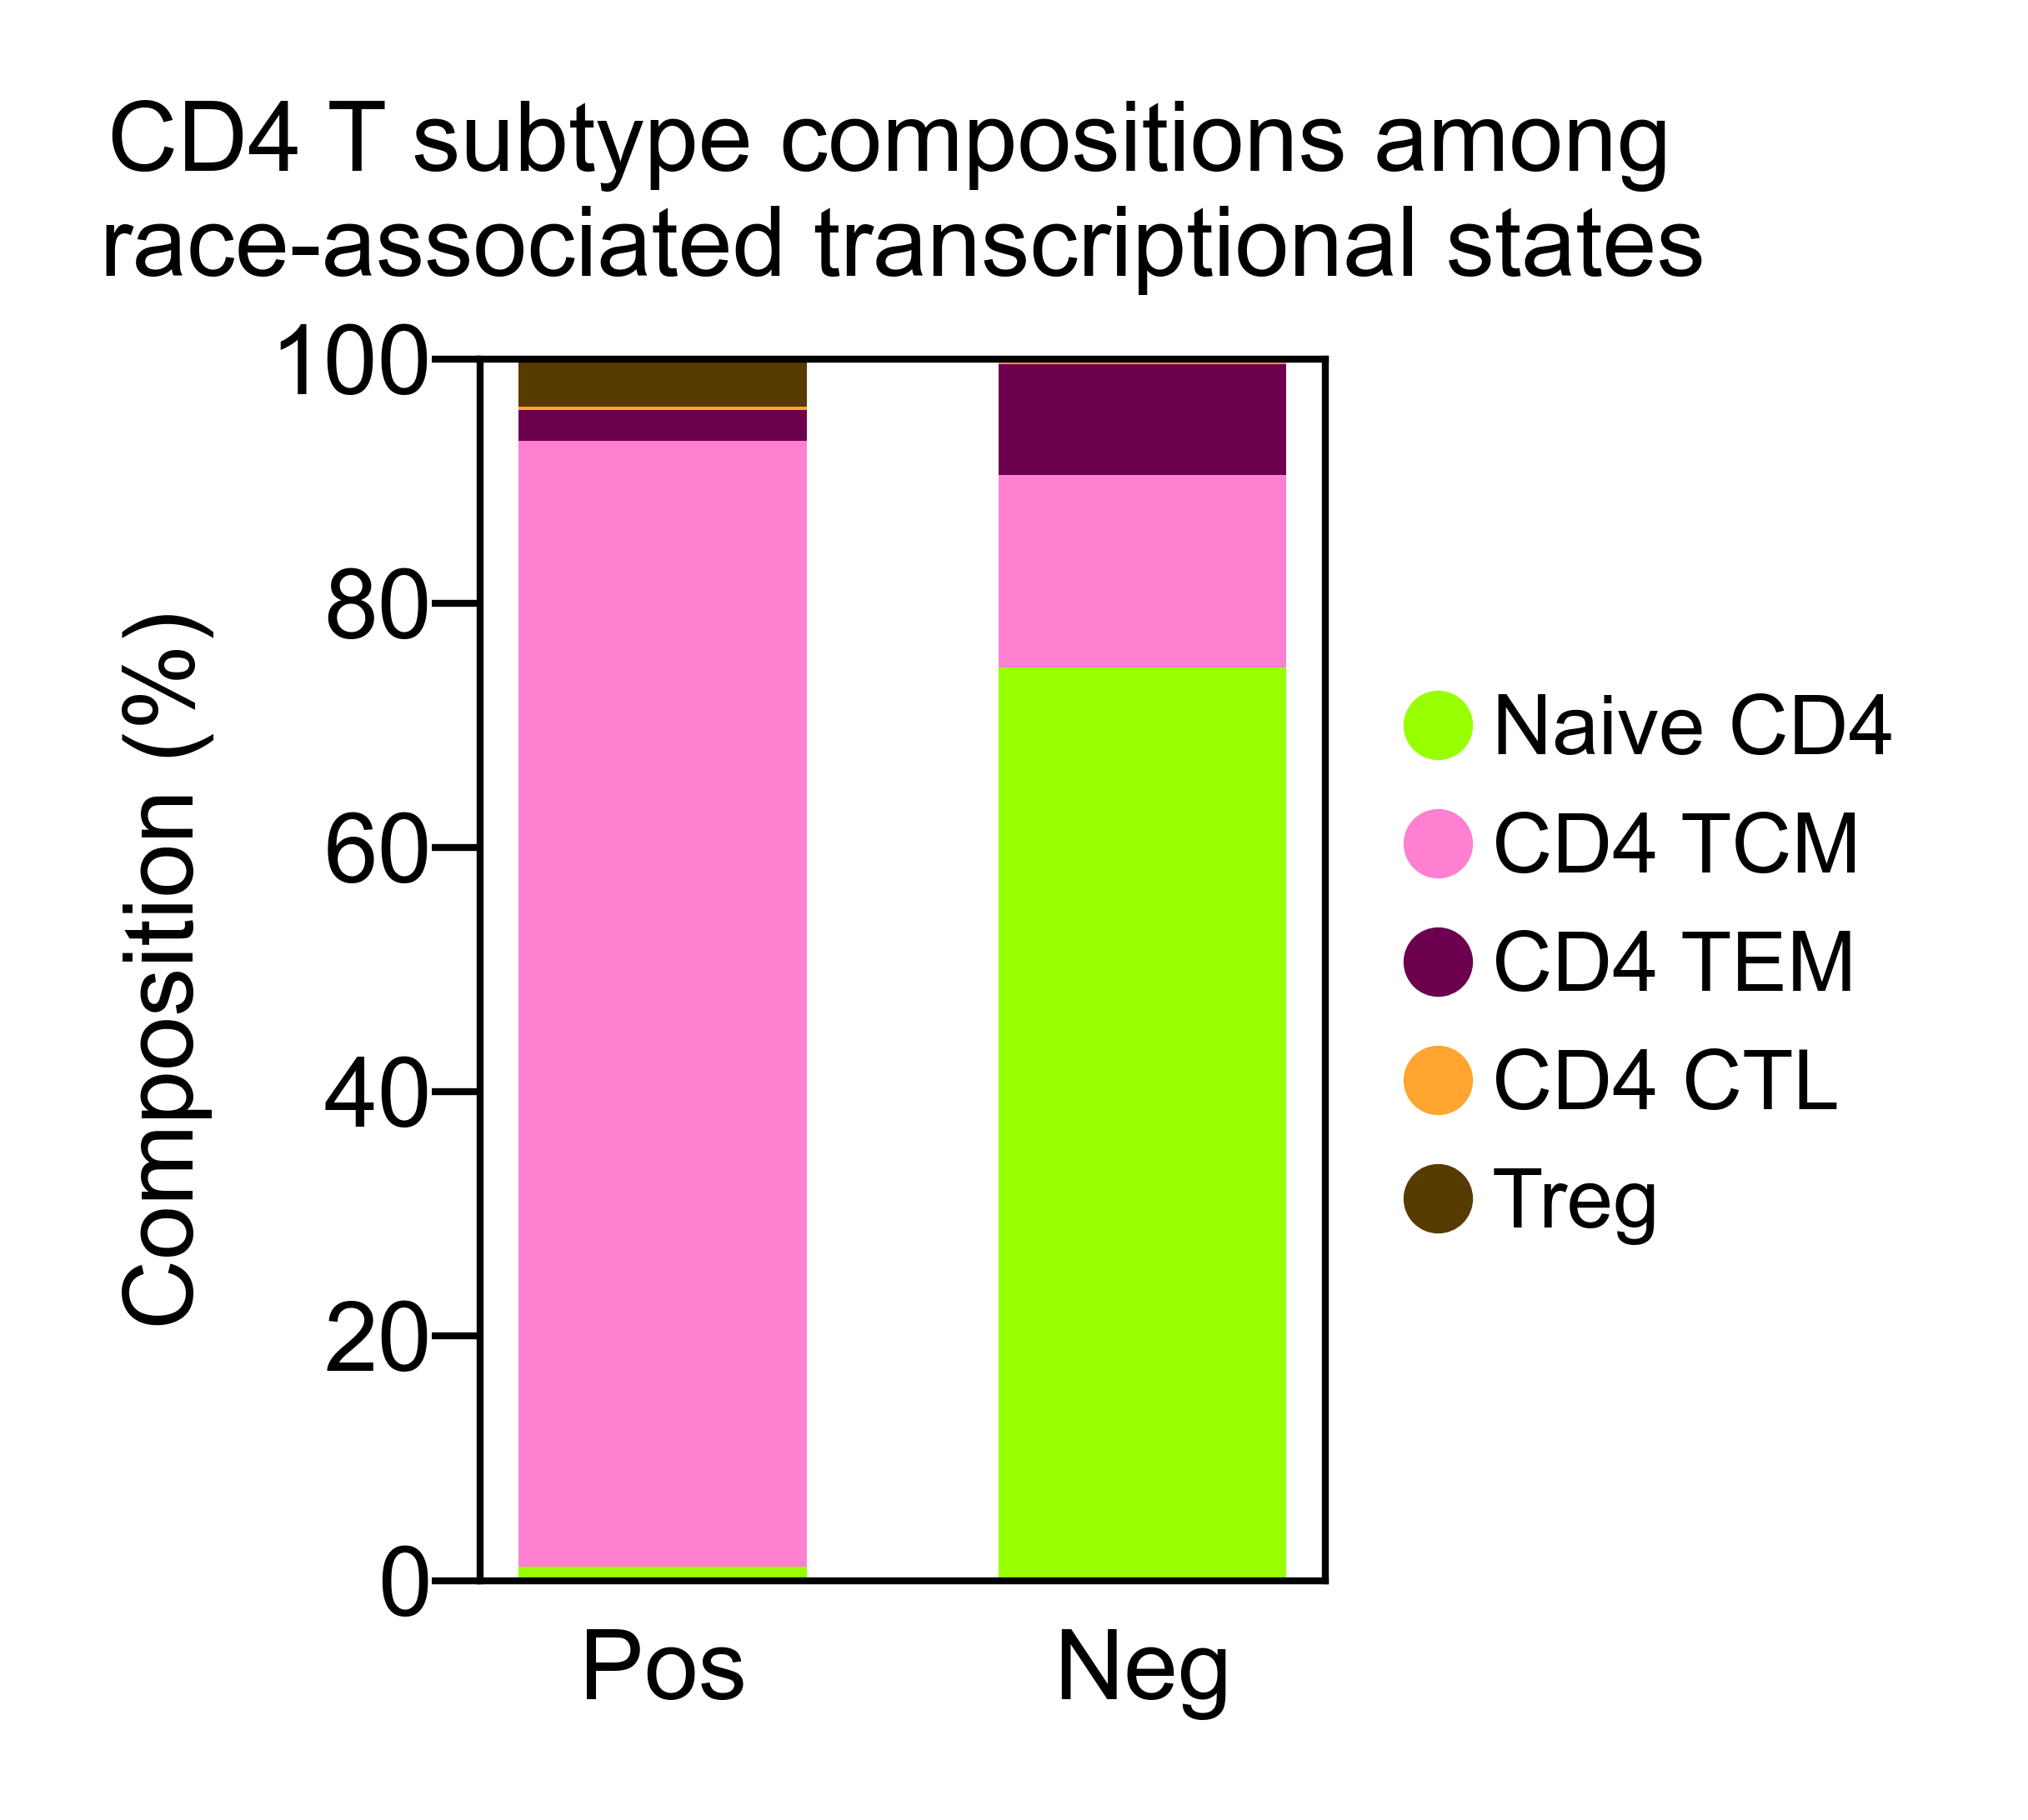

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

covar = "race"
fdr_col = f"{covar}_coef_fdr"
coef_col = f"{covar}_coef"

# positive-associated cells
tmp_pos = d[(d.obs[fdr_col] < 0.1) & (d.obs[coef_col] > 0)]
cnt_pos = Counter(tmp_pos.obs["celltype_level3"])

# negative-associated cells
tmp_neg = d[(d.obs[fdr_col] < 0.1) & (d.obs[coef_col] < 0)]
cnt_neg = Counter(tmp_neg.obs["celltype_level3"])

# all cell types appearing in either group
celltypes = sorted(set(cnt_pos.keys()) | set(cnt_neg.keys()))

# count table
df_counts = pd.DataFrame({
    "cell_type": celltypes,
    "pos_count": [cnt_pos.get(ct, 0) for ct in celltypes],
    "neg_count": [cnt_neg.get(ct, 0) for ct in celltypes],
})

# optional: keep only cell types present in your palette/order
celltype_order = [ct for ct in palette_all.keys() if ct in df_counts["cell_type"].values]
df_counts["cell_type"] = pd.Categorical(df_counts["cell_type"], categories=celltype_order, ordered=True)
df_counts = df_counts.sort_values("cell_type").reset_index(drop=True)

# calculate percentages within pos and neg separately
df_counts["pos_pct"] = df_counts["pos_count"] / df_counts["pos_count"].sum() * 100
df_counts["neg_pct"] = df_counts["neg_count"] / df_counts["neg_count"].sum() * 100

# reshape for plotting
dat = (
    df_counts
    .set_index("cell_type")[["pos_pct", "neg_pct"]]
    .T
)
dat.index = ["Pos", "Neg"]

# colors in desired order
pal_ordered = [palette_all[ct] for ct in dat.columns]

# plot
fig, ax = plt.subplots(figsize=(2,1.8))

bottom = pd.Series(0, index=dat.index)

for ct, color in zip(dat.columns, pal_ordered):
    ax.bar(
        dat.index,
        dat[ct],
        bottom=bottom,
        color=color,
        label=ct,
        width=0.6
    )
    bottom += dat[ct]

ax.set_ylabel("Composition (%)", fontsize=7)
ax.set_xlabel("")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", labelsize=7)
ax.tick_params(axis="y", labelsize=7)
ax.set_title('CD4 T subtype compositions among \nrace-associated transcriptional states')


# plot legend
from matplotlib.lines import Line2D

label_map = {
'Naive CD4T': 'Naive CD4', 
'Central Memory CD4T': 'CD4 TCM', 
'Effector Memory CD4T': 'CD4 TEM', 
'Cytotoxic CD4T': 'CD4 CTL',
'Treg':'Treg'
}

handles = [
    Line2D(
        [0], [0],
        marker='o',
        linestyle='None',
        markerfacecolor=palette_all[ct],
        markeredgecolor=palette_all[ct],
        markersize=4,
        label=label_map.get(ct, ct)
    )
    for ct in dat.columns
]

ax.legend(
    handles=handles,
    title="",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
    fontsize=6,
    handletextpad=0.4
)

plt.tight_layout()
plt.savefig("plots/S4/CD4T_asso_composition.pdf", bbox_inches="tight")
plt.show()

## Dz State

In [9]:
cts = 0

for group in ['HRL','DCIS','BC']:

    for db in ['hallmark','immport']:

        cts += 1
        
        raw = pd.read_csv(
            f'data/Figure7/CNArankNHBvsW_CD4T_{group}_{db}.csv', 
            index_col=0)
        
        dfp = raw#[raw['FDR q-val']<0.05].sort_values('NES', ascending=False)

        dfp['Tag %'] = (
            dfp['Tag %']
            .astype(str)
            .apply(lambda x: eval(x) if '/' in x else float(x))
        )
        dfp['Tag %'] = dfp['Tag %'] * 100
        dfp['log_p'] = -np.log10(dfp['FDR q-val'].replace(0, 1e-300))
        
        # Sort by NES
        dfp = dfp.sort_values('NES', ascending=False)
        
        # filter - 
        # dfp = dfp[dfp['Tag %']>=30]
        dfp['Term'] = [x.removeprefix('HALLMARK_').replace('_',' ').upper() for x in dfp['Term']]


        dfp['analysis_group'] = [group]*dfp.shape[0]
        dfp['analysis_db'] = [db]*dfp.shape[0]

        out = dfp if cts==1 else pd.concat([out, dfp])


out        

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,log_p,analysis_group,analysis_db
0,prerank,PROTEIN SECRETION,0.694535,1.816418,0.000000,0.000944,0.001,60.000000,14.34%,RPS6KA3;PAM;STAM;GOLGA4;MON2;VPS4B;ICA1;CD63;T...,3.024831,HRL,hallmark
1,prerank,MITOTIC SPINDLE,0.632587,1.748445,0.000000,0.001417,0.003,48.241206,18.94%,FLNA;MYH9;AKAP13;PREX1;EZR;TLK1;EPB41;SMC4;ROC...,2.848739,HRL,hallmark
2,prerank,PI3K AKT MTOR SIGNALING,0.650265,1.722116,0.000000,0.001574,0.005,42.156863,15.21%,CXCR4;RPS6KA3;PLCB1;CDKN1B;PRKCB;CAMK4;ACTR2;T...,2.802982,HRL,hallmark
3,prerank,HEME METABOLISM,0.595273,1.656805,0.000000,0.003306,0.013,36.082474,14.90%,HBB;NR3C1;RNF19A;TENT5C;CAST;BTG2;TNRC6B;ANK1;...,2.480763,HRL,hallmark
4,prerank,UV RESPONSE DN,0.600113,1.632388,0.000000,0.003967,0.020,41.007194,16.17%,ANXA2;CDKN1B;ATP2B4;ATXN1;ATP2B1;NR3C1;INPP4B;...,2.401581,HRL,hallmark
...,...,...,...,...,...,...,...,...,...,...,...,...,...
50,prerank,TCR SIGNALING,-0.416716,-1.382831,0.021053,0.299915,0.865,38.793103,7.79%,RPS27A;CD3E;CD3D;LCK;UBB;PSME1;UBC;LAT;PSMB8;E...,0.523001,BC,immport
38,prerank,ROS AND RNS PRODUCTION IN PHAGOCYTES,-0.542133,-1.480430,0.027451,0.206865,0.668,28.571429,7.98%,RAC2;ATP6V1G1;NCF1;ATP6V0E1;ATP6V1F;ATP6V0E2;H...,0.684313,BC,immport
9,prerank,TNFR2 NON-CANONICAL NF-KB PATHWAY,-0.532122,-1.702525,0.000000,0.041053,0.157,51.000000,12.11%,RPS27A;CD27;UBB;PSME1;UBC;PSMB8;PSMA7;PSMB9;PS...,1.386653,BC,immport
8,prerank,ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE,-0.700147,-1.709700,0.011765,0.057248,0.147,10.000000,0.15%,RPL39;FAU,1.242243,BC,immport


### HRL

In [10]:
DzState, db = 'HRL', 'immport'
qthres=.1


dfp = out[
    (out['analysis_group']==DzState) &
    (out['analysis_db']==db) &
    (out['FDR q-val']<qthres)
    ]

dfp['Term'].unique()

array(['B CELL DIFFERENTIATION', 'MONONUCLEAR CELL MIGRATION',
       'NATURAL KILLER CELL ACTIVATION', 'LEUKOCYTE CHEMOTAXIS',
       'B CELL ACTIVATION', 'T CELL DIFFERENTIATION',
       'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'NATURAL KILLER CELL DIFFERENTIATION',
       'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS',
       'LEUKOCYTE HOMEOSTASIS',
       'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
       'INTERLEUKIN-2 FAMILY SIGNALING', 'ALPHA-BETA T CELL ACTIVATION',
       'MYELOID LEUKOCYTE MIGRATION', 'COSTIMULATION BY THE CD28 FAMILY',
       'T CELL PROLIFERATION',
       'T CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'CLASS I MHC MEDIATED ANTIGEN PROCESSING & PRESENTATION',
       'ACTIVATION OF INNATE IMMUNE RESPONSE', 'RAP1 SIGNALLING',
       'INTERLEUKIN-10 SIGNALING',
       'NEGATIVE REGULATION OF IMMUNE RESPONSE',
       

In [11]:
paths_relevant = [
# 'B CELL DIFFERENTIATION', 
# 'MONONUCLEAR CELL MIGRATION',
# 'NATURAL KILLER CELL ACTIVATION', 
'LEUKOCYTE CHEMOTAXIS',
# 'B CELL ACTIVATION', 
    'T CELL DIFFERENTIATION',
'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
# 'NATURAL KILLER CELL DIFFERENTIATION',
'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
# 'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS',
'LEUKOCYTE HOMEOSTASIS', 
    'INTERLEUKIN-2 FAMILY SIGNALING',
'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
# 'MYELOID LEUKOCYTE MIGRATION', 
    'ALPHA-BETA T CELL ACTIVATION',
'COSTIMULATION BY THE CD28 FAMILY', 
    'T CELL PROLIFERATION',
'T CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
# 'CLASS I MHC MEDIATED ANTIGEN PROCESSING & PRESENTATION',
# 'ACTIVATION OF INNATE IMMUNE RESPONSE', 
    'INTERLEUKIN-10 SIGNALING',
'RAP1 SIGNALLING', 
    'NEGATIVE REGULATION OF IMMUNE RESPONSE',
# 'STIMULATORY C-TYPE LECTIN RECEPTOR SIGNALING PATHWAY',
'INTERLEUKIN-20 FAMILY SIGNALING',
'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY',
'NEGATIVE REGULATION OF CYTOPLASMIC PATTERN RECOGNITION RECEPTOR SIGNALING PATHWAY',
'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 2 SIGNALING PATHWAY',
# 'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING',
'INTERLEUKIN-12 FAMILY SIGNALING', 
    'LYMPHOCYTE PROLIFERATION',
'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE',
'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION',
# 'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 4 SIGNALING PATHWAY',
'LEUKOCYTE MEDIATED CYTOTOXICITY', 
    'TOLERANCE INDUCTION',
# 'DAP12 INTERACTIONS',
'NEGATIVE REGULATION OF IMMUNE EFFECTOR PROCESS',
# 'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY',
# 'NATURAL KILLER CELL MEDIATED CYTOTOXICITY',
'INTERFERON GAMMA SIGNALING',
'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL',
'TCR SIGNALING',
'NEGATIVE REGULATION OF ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
'INTERLEUKIN-6 FAMILY SIGNALING',
# 'NATURAL KILLER CELL MEDIATED IMMUNITY',
# 'PROLACTIN RECEPTOR SIGNALING',
'ADVANCED GLYCOSYLATION ENDPRODUCT RECEPTOR SIGNALING',
# 'NEUTROPHIL DEGRANULATION', 
    'T CELL SELECTION',
# 'SIGNALING BY THE B CELL RECEPTOR (BCR)',
'INTERLEUKIN-1 FAMILY SIGNALING',
# 'ANTIGEN PROCESSING AND PRESENTATION',
'LEUKOCYTE MEDIATED IMMUNITY', 
    'FLT3 SIGNALING',
'SOMATIC DIVERSIFICATION OF IMMUNE RECEPTORS',
'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING',
'CELLULAR EXTRAVASATION', 
#     'ANTIMICROBIAL PEPTIDES',
# 'INNATE IMMUNE RESPONSE IN MUCOSA'    
]

In [12]:
dfp_sel = dfp[dfp['Term'].isin(paths_relevant)]
dfp_sel.to_csv(f'data/Tables/CD4T_{DzState}.csv')

In [13]:
short_name_map = {
    'LEUKOCYTE CHEMOTAXIS':
        'LEUKO CHEMOTAXIS',
    'T CELL DIFFERENTIATION':
        'T CELL DIFFERENTIATION',
    'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        'LYMPHOCYTE ACTIV IN IMMUNE RESP',
    'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        'LEUKO ACTIV IN IMMUNE RESP',
    'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        'CELL ACTIV IN IMMUNE RESP',
    'LEUKOCYTE HOMEOSTASIS':
        'LEUKO HOMEOSTASIS',
    'INTERLEUKIN-2 FAMILY SIGNALING':
        'IL-2 FAMILY SIG',
    'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY':
        'AG R-MEDIATED SIG PATHWAY',
    'ALPHA-BETA T CELL ACTIVATION':
        'ALPHA-BETA T CELL ACTIV',
    'COSTIMULATION BY THE CD28 FAMILY':
        'CD28 FAMILY COSTIM',
    'T CELL PROLIFERATION':
        'T CELL PROLIFERATION',
    'T CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        'T CELL ACTIV IN IMMUNE RESP',
    'INTERLEUKIN-10 SIGNALING':
        'IL-10 SIG',
    'RAP1 SIGNALLING':
        'RAP1 SIGNALING',
    'NEGATIVE REGULATION OF IMMUNE RESPONSE':
        'NEG REG OF IMMUNE RESP',
    'INTERLEUKIN-20 FAMILY SIGNALING':
        'IL-20 FAMILY SIG',
    'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY':
        'INNATE RESP-ACTIV SIG PATHWAY',
    'NEGATIVE REGULATION OF CYTOPLASMIC PATTERN RECOGNITION RECEPTOR SIGNALING PATHWAY':
        'NEG REG OF CYTOPLASMIC PRR SIG',
    'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 2 SIGNALING PATHWAY':
        'NEG REG OF TLR2 SIG',
    'INTERLEUKIN-12 FAMILY SIGNALING':
        'IL-12 FAMILY SIG',
    'LYMPHOCYTE PROLIFERATION':
        'LYMPHOCYTE PROLIFERATION',
    'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE':
        'LEUKO MIGR IN INFLAMM RESP',
    'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION':
        'NEG REG OF LEUKO ACTIV',
    'LEUKOCYTE MEDIATED CYTOTOXICITY':
        'LEUKO MEDIATED CYTOTOX',
    'TOLERANCE INDUCTION':
        'TOLERANCE INDUCTION',
    'NEGATIVE REGULATION OF IMMUNE EFFECTOR PROCESS':
        'NEG REG OF IMMUNE EFFECTOR PROCESS',
    'INTERFERON GAMMA SIGNALING':
        'IFN-GAMMA SIG',
    'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL':
        'IMMUNOREG BET LYMPHOID-NON-LYMPHOID',
    'TCR SIGNALING':
        'TCR SIG',
    'NEGATIVE REGULATION OF ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY':
        'NEG REG OF AG R-MEDIATED SIG',
    'INTERLEUKIN-6 FAMILY SIGNALING':
        'IL-6 FAMILY SIG',
    'ADVANCED GLYCOSYLATION ENDPRODUCT RECEPTOR SIGNALING':
        'AGE-RAGE SIG',
    'T CELL SELECTION':
        'T CELL SELECTION',
    'INTERLEUKIN-1 FAMILY SIGNALING':
        'IL-1 FAMILY SIG',
    'LEUKOCYTE MEDIATED IMMUNITY':
        'LEUKO MEDIATED IMMUNITY',
    'FLT3 SIGNALING':
        'FLT3 SIG',
    'SOMATIC DIVERSIFICATION OF IMMUNE RECEPTORS':
        'SOMATIC DIVERSIF OF IMMUNE R',
    'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING':
        'IL-4, IL-13 SIG',
    'CELLULAR EXTRAVASATION':
        'CELLULAR EXTRAVASATION'
}

In [14]:
triangle_map = {
    'LEUKOCYTE CHEMOTAXIS':
        {"marker": "^", "color": "#009E57"},  # green; Migration / chemotaxis
    'T CELL DIFFERENTIATION':
        {"marker": "^", "color": "#FDBF11"},  # yellow; Mobilization / survival
    'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        {"marker": "^", "color": "#F46D1F"},  # orange; Antigen presentation related
    'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        {"marker": "^", "color": "#F46D1F"},  # orange; Antigen presentation related
    'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        {"marker": "^", "color": "#F46D1F"},  # orange; Antigen presentation related
    'LEUKOCYTE HOMEOSTASIS':
        {"marker": "^", "color": "#FDBF11"},  # yellow; Mobilization / survival
    'INTERLEUKIN-2 FAMILY SIGNALING':
        {"marker": "^", "color": "#FDBF11"},  # yellow; Mobilization / survival
    'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY':
        {"marker": "^", "color": "#F46D1F"},  # orange; Antigen presentation related
    'ALPHA-BETA T CELL ACTIVATION':
        {"marker": "^", "color": "#F46D1F"},  # orange; Antigen presentation related
    'COSTIMULATION BY THE CD28 FAMILY':
        {"marker": "^", "color": "#F46D1F"},  # orange; Antigen presentation related
    'T CELL PROLIFERATION':
        {"marker": "^", "color": "#FDBF11"},  # yellow; Mobilization / survival
    'T CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        {"marker": "^", "color": "#F46D1F"},  # orange; Antigen presentation related
    'INTERLEUKIN-10 SIGNALING':
        {"marker": "^", "color": "#F46D1F"},  # orange; Antigen presentation related
    'RAP1 SIGNALLING':
        {"marker": "^", "color": "#009E57"},  # green; Migration / chemotaxis
    'NEGATIVE REGULATION OF IMMUNE RESPONSE':
        {"marker": "^", "color": "#2CA9E1"},  # blue; Phagocytosis
    'INTERLEUKIN-20 FAMILY SIGNALING':
        {"marker": "^", "color": "#F46D1F"},  # orange; Antigen presentation related
    'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY':
        {"marker": "^", "color": "#7B4F2A"},  # brown; Antimicrobial response
    'NEGATIVE REGULATION OF CYTOPLASMIC PATTERN RECOGNITION RECEPTOR SIGNALING PATHWAY':
        {"marker": "^", "color": "#2CA9E1"},  # blue; Phagocytosis
    'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 2 SIGNALING PATHWAY':
        {"marker": "^", "color": "#2CA9E1"},  # blue; Phagocytosis
    'INTERLEUKIN-12 FAMILY SIGNALING':
        {"marker": "^", "color": "#F46D1F"},  # orange; Antigen presentation related
    'LYMPHOCYTE PROLIFERATION':
        {"marker": "^", "color": "#FDBF11"},  # yellow; Mobilization / survival
    'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE':
        {"marker": "^", "color": "#009E57"},  # green; Migration / chemotaxis
    'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION':
        {"marker": "^", "color": "#2CA9E1"},  # blue; Phagocytosis
    'LEUKOCYTE MEDIATED CYTOTOXICITY':
        {"marker": "^", "color": "#F46D1F"},  # orange; Antigen presentation related
    'TOLERANCE INDUCTION':
        {"marker": "^", "color": "#2CA9E1"},  # blue; Phagocytosis
    'NEGATIVE REGULATION OF IMMUNE EFFECTOR PROCESS':
        {"marker": "^", "color": "#2CA9E1"},  # blue; Phagocytosis
    'INTERFERON GAMMA SIGNALING':
        {"marker": "^", "color": "#F46D1F"},  # orange; Antigen presentation related
    'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL':
        {"marker": "^", "color": "#2CA9E1"},  # blue; Phagocytosis
    'TCR SIGNALING':
        {"marker": "^", "color": "#F46D1F"},  # orange; Antigen presentation related
    'NEGATIVE REGULATION OF ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY':
        {"marker": "^", "color": "#2CA9E1"},  # blue; Phagocytosis
    'INTERLEUKIN-6 FAMILY SIGNALING':
        {"marker": "^", "color": "#F46D1F"},  # orange; Antigen presentation related
    'ADVANCED GLYCOSYLATION ENDPRODUCT RECEPTOR SIGNALING':
        {"marker": "^", "color": "#F46D1F"},  # orange; Antigen presentation related
    'T CELL SELECTION':
        {"marker": "^", "color": "#FDBF11"},  # yellow; Mobilization / survival
    'INTERLEUKIN-1 FAMILY SIGNALING':
        {"marker": "^", "color": "#F46D1F"},  # orange; Antigen presentation related
    'LEUKOCYTE MEDIATED IMMUNITY':
        {"marker": "^", "color": "#F46D1F"},  # orange; Antigen presentation related
    'FLT3 SIGNALING':
        {"marker": "^", "color": "#FDBF11"},  # yellow; Mobilization / survival
    'SOMATIC DIVERSIFICATION OF IMMUNE RECEPTORS':
        {"marker": "^", "color": "#FDBF11"},  # yellow; Mobilization / survival
    'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING':
        {"marker": "^", "color": "#F46D1F"},  # orange; Antigen presentation related
    'CELLULAR EXTRAVASATION':
        {"marker": "^", "color": "#009E57"}   # green; Migration / chemotaxis
}

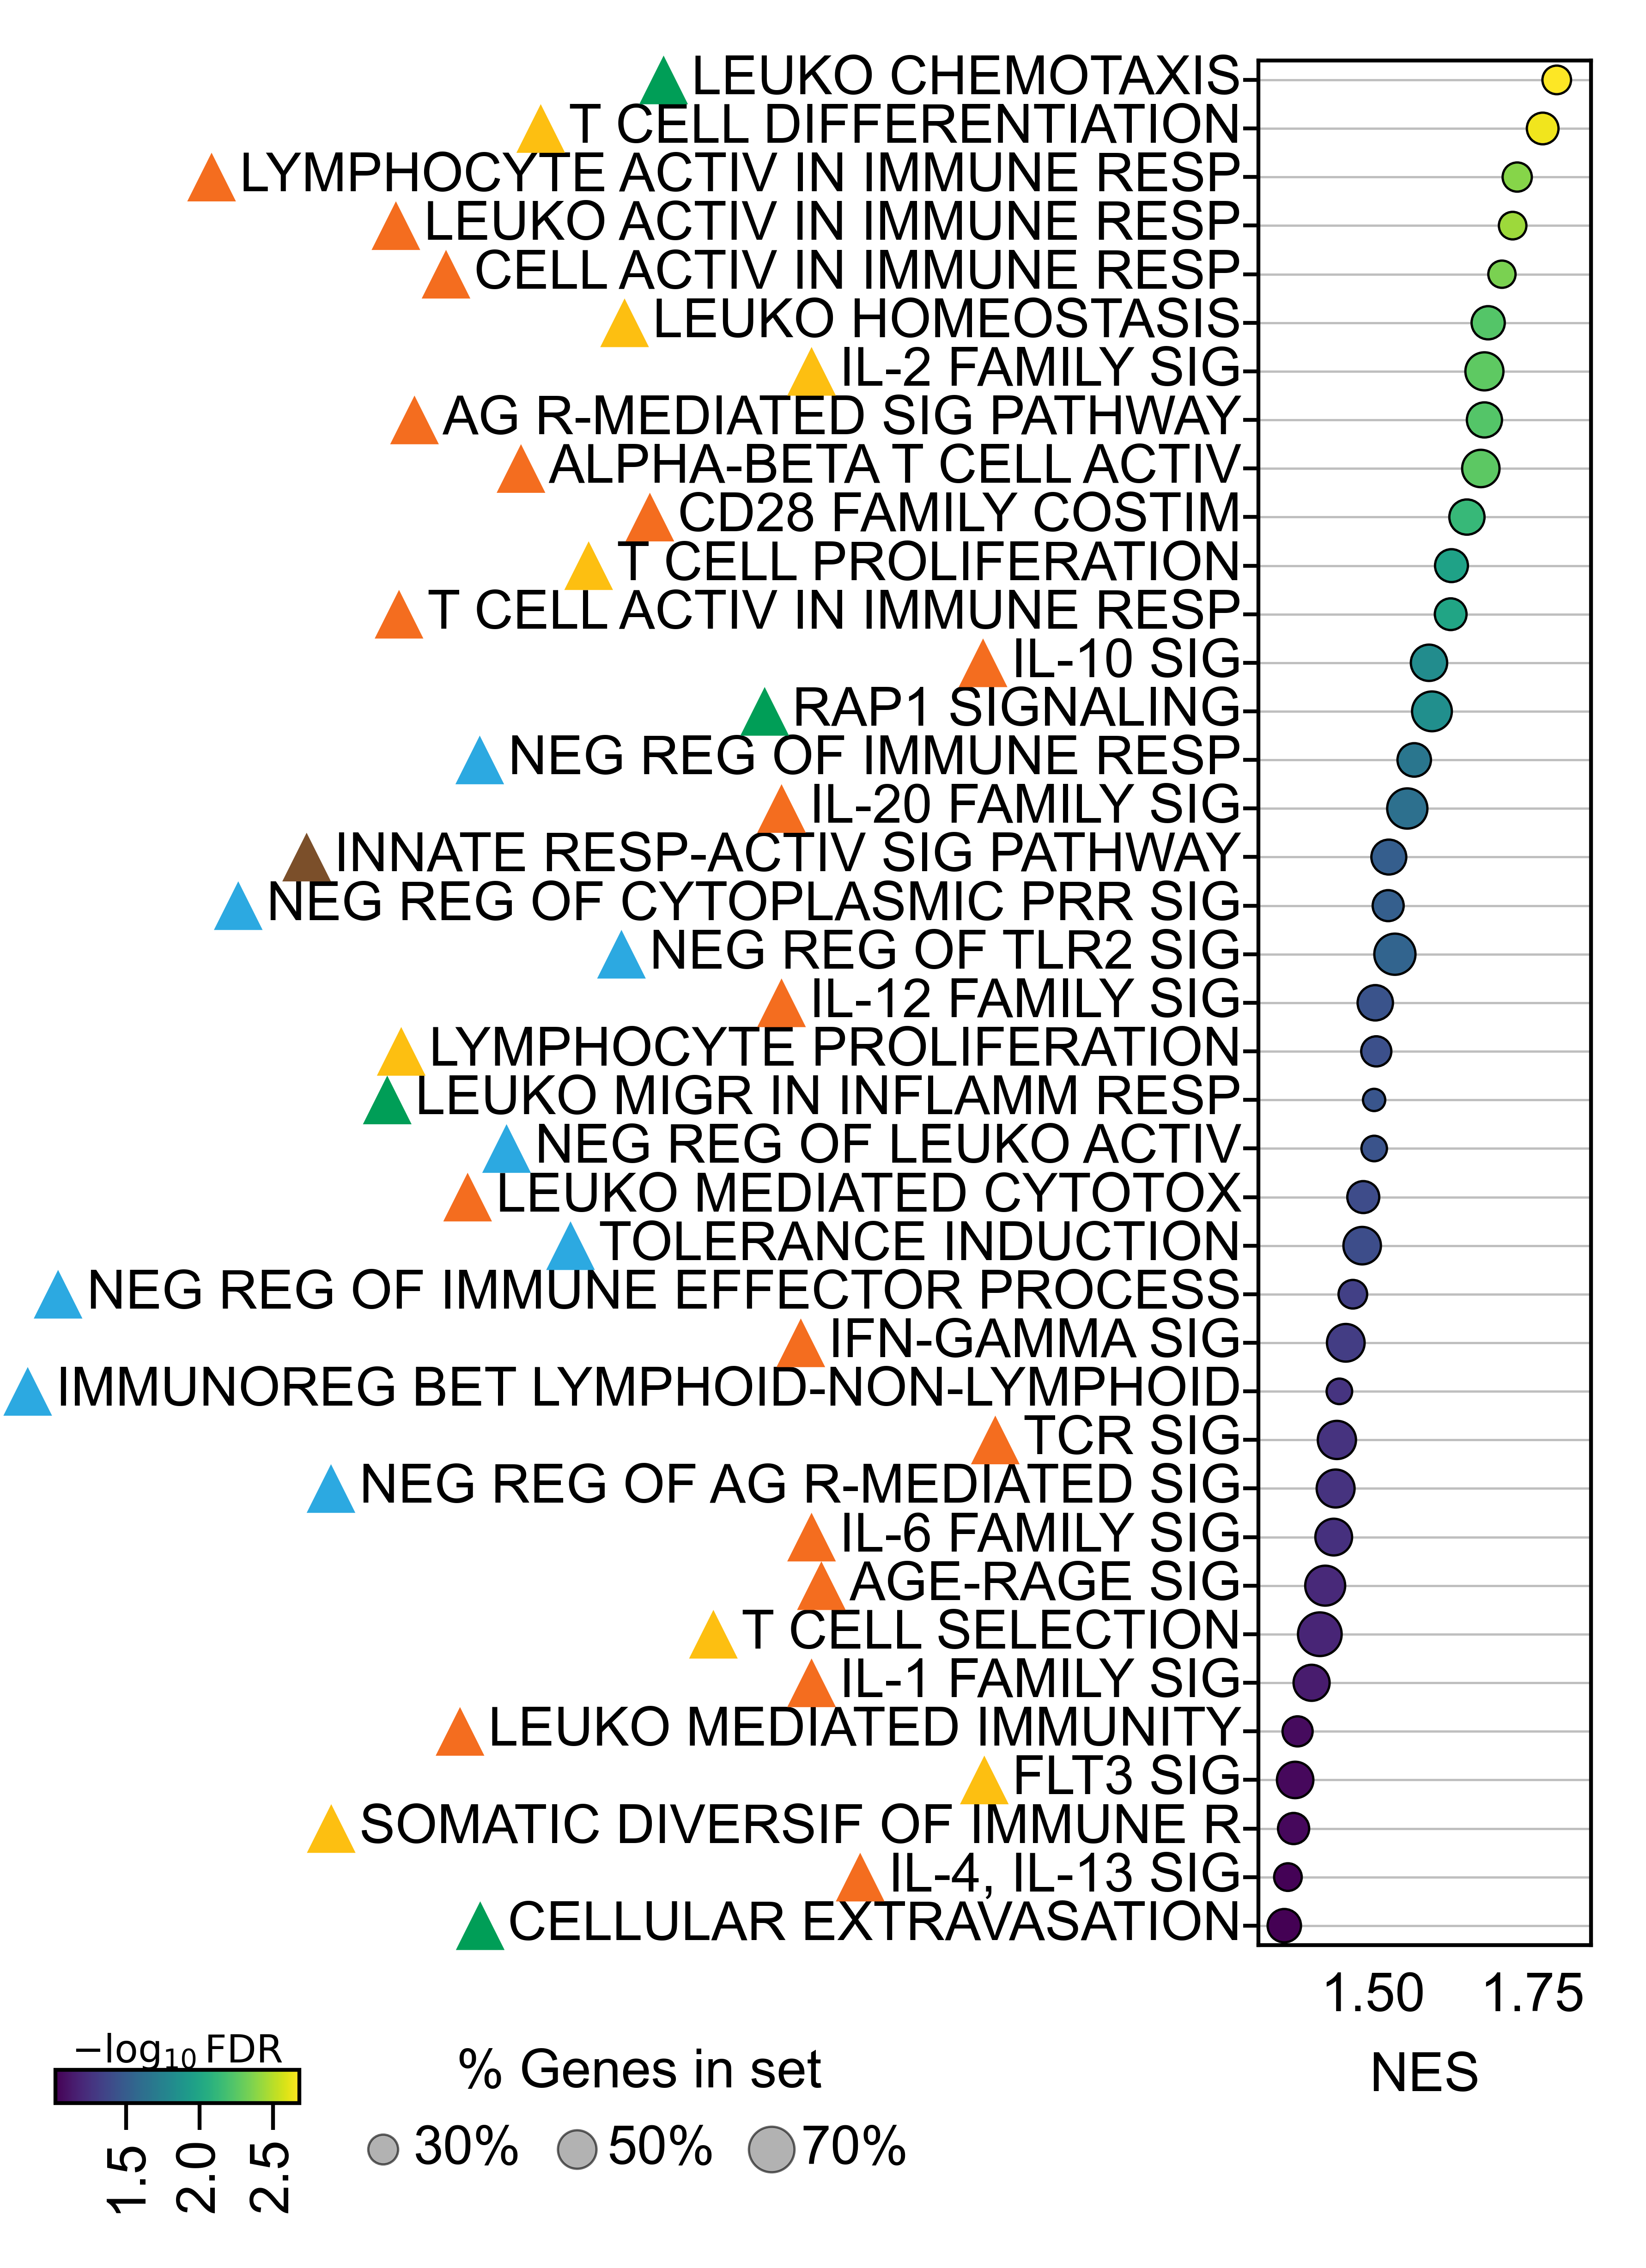

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
from textwrap import fill
from matplotlib import font_manager as fm

title_map = {"HRL": "High-Risk Lesion", "DCIS": "DCIS", "BC": "Breast Cancer"}

# -----------------------------
# Prepare data
# -----------------------------
dfp2 = dfp[dfp["Term"].isin(paths_relevant)].copy()
dfp2["Term"] = pd.Categorical(dfp2["Term"], categories=paths_relevant, ordered=True)
dfp2 = dfp2.sort_values("Term").reset_index(drop=True)

dfp2["Term_full"] = dfp2["Term"].astype(str)
dfp2["Term_short"] = dfp2["Term_full"].map(short_name_map).fillna(dfp2["Term_full"])
dfp2["Term_plot"] = dfp2["Term_short"].apply(lambda x: fill(str(x), width=38))

# -----------------------------
# Parameters
# -----------------------------
dot_scale = 0.5
cmap = plt.cm.viridis
arial_font = fm.FontProperties(family="Arial")

label_fontsize = 7
label_right_x = -0.05

triangle_gap_px = 20
triangle_size = 40
triangle_half_width_px = 10

# -----------------------------
# Plot
# -----------------------------
fig, ax = plt.subplots(figsize=(2, 5))

# Main control:
# larger left = wider ylabel region + narrower bubble box
fig.subplots_adjust(left=0.68, right=0.98, bottom=0.24, top=0.92)

ypos = list(range(len(dfp2)))

sc = ax.scatter(
    dfp2["NES"],
    ypos,
    s=dfp2["Tag %"] * dot_scale,
    c=dfp2["log_p"],
    cmap=cmap,
    edgecolor="black",
    linewidth=0.3,
    zorder=3
)

# -----------------------------
# Manual y labels
# -----------------------------
ax.set_yticks(ypos)
ax.set_yticklabels([])
ax.invert_yaxis()
# shrink top/bottom padding inside bubble box
y_pad = 0.4
ax.set_ylim(len(dfp2) - 1 + y_pad, -y_pad)


label_text_objects = []

for i, row in dfp2.iterrows():
    txt = ax.text(
        label_right_x,
        i,
        row["Term_plot"],
        transform=ax.get_yaxis_transform(),
        ha="right",
        va="center",
        fontsize=label_fontsize,
        clip_on=False
    )
    label_text_objects.append((txt, row["Term_full"], i))

# -----------------------------
# Axes formatting
# -----------------------------
nes_max = dfp2["NES"].abs().max()
nes_min = dfp2["NES"].min()
ax.set_xlim([nes_min * .97, nes_max * 1.03])

ax.set_xlabel("NES", fontsize=7)
ax.set_ylabel("")
ax.tick_params(axis="x", labelsize=7)
ax.tick_params(axis="y", length=2, labelsize=6, pad=1)
ax.set_title('')#(title_map.get(DzState, DzState), fontsize=10, pad=8)

ax.grid(axis="y", linestyle="-", linewidth=0.3, color="gray", alpha=0.5, zorder=0)
ax.axvline(x=0, linestyle="--", linewidth=0.7, color="gray", alpha=0.8, zorder=1)

# -----------------------------
# Draw once, then measure manual labels
# -----------------------------
fig.canvas.draw()
renderer = fig.canvas.get_renderer()

label_bboxes = [
    txt.get_window_extent(renderer=renderer)
    for txt, term_full, i in label_text_objects
]

leftmost_label_x_display = min(b.x0 for b in label_bboxes)
lowest_label_y_display = min(b.y0 for b in label_bboxes)

leftmost_label_x_fig, lowest_label_y_fig = fig.transFigure.inverted().transform(
    (leftmost_label_x_display, lowest_label_y_display)
)

# -----------------------------
# Triangles immediately left of labels
# -----------------------------
for txt, term_full, i in label_text_objects:
    tri = triangle_map.get(term_full)
    if tri is None:
        continue

    bbox = txt.get_window_extent(renderer=renderer)
    triangle_x_display = bbox.x0 - triangle_gap_px - triangle_half_width_px
    triangle_x_axes = ax.transAxes.inverted().transform((triangle_x_display, bbox.y0))[0]

    ax.scatter(
        triangle_x_axes,
        i,
        marker=tri["marker"],
        s=triangle_size,
        color=tri["color"],
        edgecolor="none",
        transform=ax.get_yaxis_transform(),
        clip_on=False,
        zorder=5
    )

# -----------------------------
# Colorbar: left aligned to leftmost ylabel
# -----------------------------
cbar_left = leftmost_label_x_fig
cbar_bottom = lowest_label_y_fig - 0.055
cbar_width = 0.22
cbar_height = 0.012

cax = fig.add_axes([cbar_left, cbar_bottom, cbar_width, cbar_height])

cbar = fig.colorbar(sc, cax=cax, orientation="horizontal")
cbar.set_label(
    r"$-\log_{10}\mathrm{FDR}$",
    fontproperties=arial_font,
    fontsize=5,
    labelpad=1
)
cbar.ax.xaxis.set_label_position("top")
cbar.ax.xaxis.set_ticks_position("bottom")
cbar.ax.tick_params(labelsize=7, pad=1, rotation=90)
cbar.solids.set_rasterized(True)

# -----------------------------
# Bubble legend: right of colorbar
# -----------------------------
size_handles = [
    plt.scatter(
        [], [],
        s=size * dot_scale,
        c="gray",
        alpha=0.6,
        edgecolor="black",
        linewidth=0.3
    )
    for size in [30, 50, 70]
]

bubble_legend_x = cbar_left + cbar_width * 1.2
bubble_legend_y = cbar_bottom - 0.003

leg = fig.legend(
    size_handles,
    ["30%", "50%", "70%"],
    title="% Genes in set",
    title_fontsize=7,
    fontsize=7,
    frameon=False,
    loc="center left",
    bbox_to_anchor=(bubble_legend_x, bubble_legend_y),
    ncol=3,
    columnspacing=0.8,
    handletextpad=0.3,
    borderaxespad=0
)

# -----------------------------
# Save
# -----------------------------
plt.savefig(
    f"plots/F6/Bubble_CD4T_{DzState}.png",
    bbox_inches="tight",
    pad_inches=0.2, 
    dpi=600
)

plt.show()

### DCIS

In [13]:
DzState, db = 'DCIS', 'immport'
qthres=.1


dfp = out[
    (out['analysis_group']==DzState) &
    (out['analysis_db']==db) &
    (out['FDR q-val']<qthres)
    ]

dfp['Term'].unique()

array(['INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING',
       'NEGATIVE REGULATION OF HEMOPOIESIS',
       'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 4 SIGNALING PATHWAY',
       'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
       'INTERLEUKIN-17 SIGNALING',
       'INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS',
       'T CELL DIFFERENTIATION', 'INTERLEUKIN-6 FAMILY SIGNALING',
       'DDX58/IFIH1-MEDIATED INDUCTION OF INTERFERON-ALPHA/BETA',
       'T CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'TOLL-LIKE RECEPTOR CASCADES', 'B CELL DIFFERENTIATION',
       'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION',
       'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 2 SIGNALING PATHWAY',
       'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING',
       'STIMULATORY C-TYPE LECTIN RECEPTOR SIGNALING PATHWAY',
     

In [14]:
# paths_sel = [
# 'NEGATIVE REGULATION OF HEMOPOIESIS',
# 'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING',
# 'INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS',
# # 'B CELL DIFFERENTIATION',
# # 'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
# 'T CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
# 'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
# # 'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 4 SIGNALING PATHWAY',
# # 'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
# # 'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
# 'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION',
# 'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
# # 'B CELL ACTIVATION', 
# 'INTERLEUKIN-6 FAMILY SIGNALING',
# 'T CELL DIFFERENTIATION',
# 'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
# 'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
# 'ALPHA-BETA T CELL ACTIVATION',
# # 'STIMULATORY C-TYPE LECTIN RECEPTOR SIGNALING PATHWAY',
# # 'NATURAL KILLER CELL ACTIVATION',
# 'INTERLEUKIN-20 FAMILY SIGNALING',
# 'INTERLEUKIN-2 FAMILY SIGNALING',
# 'COSTIMULATION BY THE CD28 FAMILY',
# # 'NATURAL KILLER CELL DIFFERENTIATION',
# # 'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 2 SIGNALING PATHWAY',
# # 'DDX58/IFIH1-MEDIATED INDUCTION OF INTERFERON-ALPHA/BETA',
# 'SOMATIC DIVERSIFICATION OF IMMUNE RECEPTORS',
# # 'ACTIVATION OF INNATE IMMUNE RESPONSE', 
# 'TOLERANCE INDUCTION',
# 'LEUKOCYTE HOMEOSTASIS', 
# # 'TOLL-LIKE RECEPTOR CASCADES',
# # 'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY',
# 'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING',
# 'INTERFERON ALPHA/BETA SIGNALING',
# 'ROS AND RNS PRODUCTION IN PHAGOCYTES',
# 'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',
# 'T CELL MEDIATED CYTOTOXICITY',
# 'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL',
# 'TNFR2 NON-CANONICAL NF-KB PATHWAY',
# # 'ANTIMICROBIAL HUMORAL RESPONSE',
# # 'INNATE IMMUNE RESPONSE IN MUCOSA'    
# ]

paths_relevant = [
    'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING',  # keep: Th2/type-2 CD4 T-cell cytokine axis
    # 'NEGATIVE REGULATION OF HEMOPOIESIS',  # exclude/weak: hematopoiesis regulation, not a clean peripheral blood CD4 T-cell function
    'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 4 SIGNALING PATHWAY',  # keep/conditional: immune regulatory/inflammatory restraint; less T-cell intrinsic but can reflect regulatory immune state
    # 'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',  # exclude: Fc receptor biology is more monocyte/NK/B-cell/myeloid than CD4 T-cell intrinsic
    'INTERLEUKIN-17 SIGNALING',  # keep: Th17-associated inflammatory signaling axis
    'INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS',  # keep: antigen-driven inflammatory activation is relevant to CD4 T-cell response
    'T CELL DIFFERENTIATION',  # keep: directly CD4 T-cell relevant
    'INTERLEUKIN-6 FAMILY SIGNALING',  # keep: IL-6 family supports CD4 T-cell differentiation/inflammatory polarization, especially Th17/Tfh-like contexts
    # 'DDX58/IFIH1-MEDIATED INDUCTION OF INTERFERON-ALPHA/BETA',  # exclude/conditional: antiviral innate sensing pathway, less CD4 T-cell specific
    'T CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',  # keep: directly CD4 T-cell relevant
    # 'TOLL-LIKE RECEPTOR CASCADES',  # exclude/conditional: innate/myeloid PRR pathway; keep only if leading-edge genes suggest T-cell intrinsic TLR response
    # 'B CELL DIFFERENTIATION',  # exclude: B-cell lineage pathway
    'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION',  # keep: immunoregulatory/tolerance-related CD4 T-cell state, especially Treg-like interpretation
    # 'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',  # exclude: phagocytosis/FcγR pathway, not CD4 T-cell intrinsic
    # 'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',  # exclude: phagocytosis pathway, not CD4 T-cell intrinsic
    'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 2 SIGNALING PATHWAY',  # keep/conditional: immune regulatory/inflammatory restraint; less T-cell intrinsic but acceptable if regulatory module
    'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING',  # keep/conditional: GM-CSF/IL-5 can reflect activated CD4 helper programs, though mixed and not CD4-specific
    # 'STIMULATORY C-TYPE LECTIN RECEPTOR SIGNALING PATHWAY',  # exclude: CLR signaling is mainly myeloid/DC antigen uptake/PRR biology
    'TOLERANCE INDUCTION',  # keep: relevant to CD4 Treg/tolerance biology
    'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY',  # keep/conditional: broad inflammatory activation; less CD4-specific but may capture activated immune state
    # 'B CELL ACTIVATION',  # exclude: B-cell pathway
    'ACTIVATION OF INNATE IMMUNE RESPONSE',  # keep/conditional: broad inflammatory activation, but not CD4-specific; inspect leading-edge genes
    'IMMUNE RESPONSE TO TUMOR CELL',  # keep: CD4 T cells can mediate antitumor helper/immunoregulatory responses
    'TNFR2 NON-CANONICAL NF-KB PATHWAY',  # keep: TNFR2/NF-kB signaling is relevant to activated/Treg CD4 T-cell survival/function
    # 'ROS AND RNS PRODUCTION IN PHAGOCYTES',  # exclude: phagocyte oxidative burst pathway, not CD4 T-cell intrinsic
    # 'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',  # exclude/weak: tissue-context pathway, less clean for peripheral blood CD4 T cells
    # 'INNATE IMMUNE RESPONSE IN MUCOSA',  # exclude: mucosal/tissue-specific innate pathway, not peripheral blood CD4 T-cell specific
    # 'ANTIMICROBIAL HUMORAL RESPONSE',  # exclude: humoral/soluble antimicrobial pathway, not CD4 T-cell intrinsic
    'T CELL MEDIATED CYTOTOXICITY',  # keep/conditional: relevant if CD4 cytotoxic T-cell program; otherwise more CD8/NK-like
    'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL'  # keep: CD4 T-cell interaction with APC/non-lymphoid cells
]

In [15]:
dfp_sel = dfp[dfp['Term'].isin(paths_relevant)]
dfp_sel.to_csv(f'data/Tables/CD4T_{DzState}.csv')

In [41]:
short_name_map = {
    'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING':
        'IL-4, IL-13 SIG',
    'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 4 SIGNALING PATHWAY':
        'NEG REG OF TLR4 SIG',
    'INTERLEUKIN-17 SIGNALING':
        'IL-17 SIG',
    'INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS':
        'INFLAMM RESP TO AG STIMULUS',
    'T CELL DIFFERENTIATION':
        'T CELL DIFFERENTIATION',
    'INTERLEUKIN-6 FAMILY SIGNALING':
        'IL-6 FAMILY SIG',
    'T CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        'T CELL ACTIV IN IMMUNE RESP',
    'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION':
        'NEG REG OF LEUKO ACTIV',
    'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 2 SIGNALING PATHWAY':
        'NEG REG OF TLR2 SIG',
    'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING':
        'IL-3, IL-5, GM-CSF SIG',
    'TOLERANCE INDUCTION':
        'TOLERANCE INDUCTION',
    'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY':
        'INNATE RESP-ACTIV SIG PATHWAY',
    'ACTIVATION OF INNATE IMMUNE RESPONSE':
        'ACTIV OF INNATE IMMUNE RESP',
    'IMMUNE RESPONSE TO TUMOR CELL':
        'IMMUNE RESP TO TUMOR CELL',
    'TNFR2 NON-CANONICAL NF-KB PATHWAY':
        'TNFR2 NON-CANONICAL NF-KB',
    'T CELL MEDIATED CYTOTOXICITY':
        'T CELL MEDIATED CYTOTOX',
    'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL':
        'IMMUNOREG BET LYMPHOID-NON-LYMPHOID'
}

In [44]:
triangle_map = {
    'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING':
        {"marker": "^", "color": "#F46D1F"},  # Activation / inflammatory signaling; type-2 helper T-cell cytokine signaling

    'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 4 SIGNALING PATHWAY':
        {"marker": "^", "color": "#2CA9E1"},  # Regulation / tolerance; suppresses innate inflammatory TLR4 signaling

    'INTERLEUKIN-17 SIGNALING':
        {"marker": "^", "color": "#F46D1F"},  # Activation / inflammatory signaling; Th17-associated inflammatory axis

    'INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS':
        {"marker": "^", "color": "#F46D1F"},  # Activation / inflammatory signaling; antigen-driven inflammatory activation

    'T CELL DIFFERENTIATION':
        {"marker": "^", "color": "#FDBF11"},  # Differentiation / proliferation / homeostasis; direct T-cell state differentiation

    'INTERLEUKIN-6 FAMILY SIGNALING':
        {"marker": "^", "color": "#F46D1F"},  # Activation / inflammatory signaling; IL-6 supports inflammatory CD4 polarization

    'T CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        {"marker": "^", "color": "#F46D1F"},  # Activation / inflammatory signaling; direct T-cell activation program

    'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION':
        {"marker": "^", "color": "#2CA9E1"},  # Regulation / tolerance; restrains leukocyte/T-cell activation

    'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 2 SIGNALING PATHWAY':
        {"marker": "^", "color": "#2CA9E1"},  # Regulation / tolerance; suppresses innate inflammatory TLR2 signaling

    'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING':
        {"marker": "^", "color": "#F46D1F"},  # Activation / inflammatory signaling; GM-CSF/IL-5 can reflect activated helper/inflammatory programs

    'TOLERANCE INDUCTION':
        {"marker": "^", "color": "#2CA9E1"},  # Regulation / tolerance; tolerance/Treg-like immune restraint

    'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY':
        {"marker": "^", "color": "#7B4F2A"},  # Innate-like immune response; broad innate-response activation

    'ACTIVATION OF INNATE IMMUNE RESPONSE':
        {"marker": "^", "color": "#7B4F2A"},  # Innate-like immune response; broad innate activation program

    'IMMUNE RESPONSE TO TUMOR CELL':
        {"marker": "v", "color": "#F46D1F"},  # Activation / inflammatory signaling; antitumor immune activation context

    'TNFR2 NON-CANONICAL NF-KB PATHWAY':
        {"marker": "v", "color": "#F46D1F"},  # Activation / inflammatory signaling; TNF/NF-kB activation/survival signaling

    'T CELL MEDIATED CYTOTOXICITY':
        {"marker": "v", "color": "#F46D1F"},  # Activation / inflammatory signaling; cytotoxic T-cell effector program

    'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL':
        {"marker": "v", "color": "#2CA9E1"}   # Regulation / tolerance; immunoregulatory lymphoid–non-lymphoid interaction
}

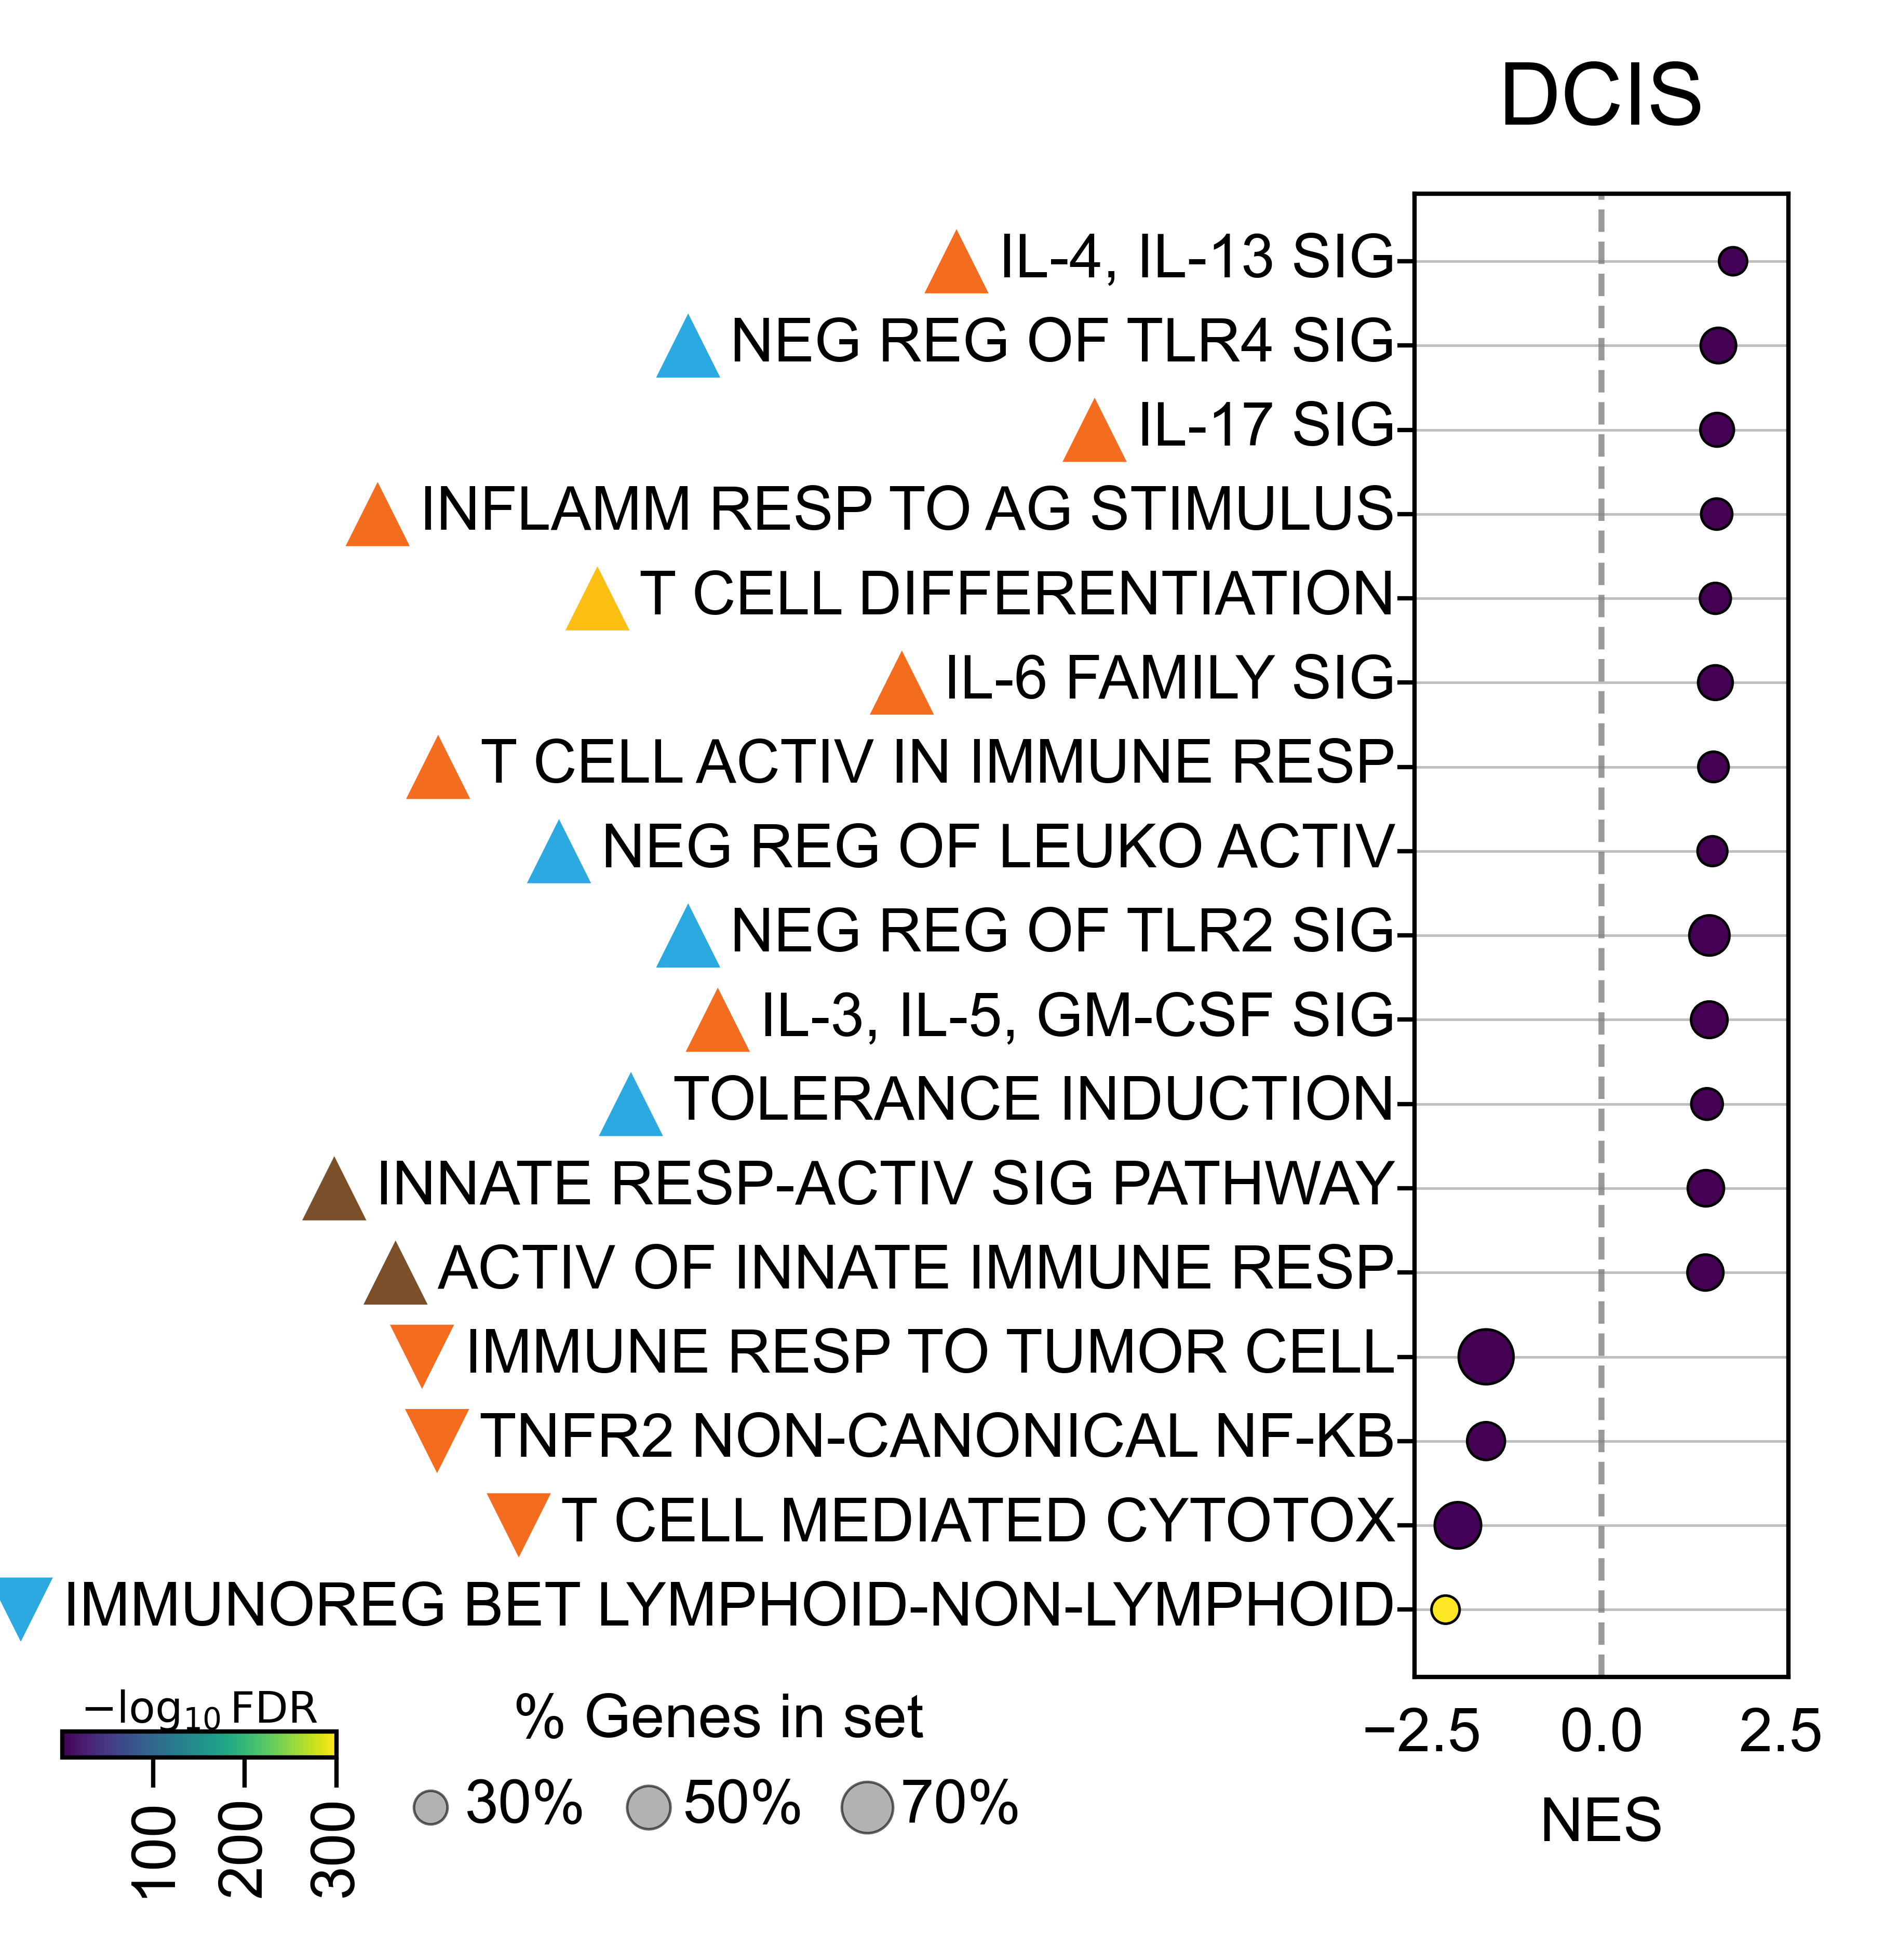

In [45]:
import pandas as pd
import matplotlib.pyplot as plt
from textwrap import fill
from matplotlib import font_manager as fm

title_map = {"HRL": "High-Risk Lesion", "DCIS": "DCIS", "BC": "Breast Cancer"}

# -----------------------------
# Prepare data
# -----------------------------
dfp2 = dfp[dfp["Term"].isin(paths_relevant)].copy()
dfp2["Term"] = pd.Categorical(dfp2["Term"], categories=paths_relevant, ordered=True)
dfp2 = dfp2.sort_values("Term").reset_index(drop=True)

dfp2["Term_full"] = dfp2["Term"].astype(str)
dfp2["Term_short"] = dfp2["Term_full"].map(short_name_map).fillna(dfp2["Term_full"])
dfp2["Term_plot"] = dfp2["Term_short"].apply(lambda x: fill(str(x), width=38))

# -----------------------------
# Parameters
# -----------------------------
dot_scale = 0.5
cmap = plt.cm.viridis
arial_font = fm.FontProperties(family="Arial")

label_fontsize = 7
label_right_x = -0.05

triangle_gap_px = 30
triangle_size = 55
triangle_half_width_px = 10

# -----------------------------
# Plot
# -----------------------------
fig, ax = plt.subplots(figsize=(2, 3.5))

# Main control:
# larger left = wider ylabel region + narrower bubble box
fig.subplots_adjust(left=0.68, right=0.98, bottom=0.24, top=0.92)

ypos = list(range(len(dfp2)))

sc = ax.scatter(
    dfp2["NES"],
    ypos,
    s=dfp2["Tag %"] * dot_scale,
    c=dfp2["log_p"],
    cmap=cmap,
    edgecolor="black",
    linewidth=0.3,
    zorder=3
)

# -----------------------------
# Manual y labels
# -----------------------------
ax.set_yticks(ypos)
ax.set_yticklabels([])
ax.invert_yaxis()

label_text_objects = []

for i, row in dfp2.iterrows():
    txt = ax.text(
        label_right_x,
        i,
        row["Term_plot"],
        transform=ax.get_yaxis_transform(),
        ha="right",
        va="center",
        fontsize=label_fontsize,
        clip_on=False
    )
    label_text_objects.append((txt, row["Term_full"], i))

# -----------------------------
# Axes formatting
# -----------------------------
nes_max = dfp2["NES"].abs().max()
nes_min = dfp2["NES"].min()
ax.set_xlim([nes_min * 1.2, nes_max * 1.2])

ax.set_xlabel("NES", fontsize=7)
ax.set_ylabel("")
ax.tick_params(axis="x", labelsize=7)
ax.tick_params(axis="y", length=2, labelsize=6, pad=1)
ax.set_title(title_map.get(DzState, DzState), fontsize=10, pad=8)

ax.grid(axis="y", linestyle="-", linewidth=0.3, color="gray", alpha=0.5, zorder=0)
ax.axvline(x=0, linestyle="--", linewidth=0.7, color="gray", alpha=0.8, zorder=1)

# -----------------------------
# Draw once, then measure manual labels
# -----------------------------
fig.canvas.draw()
renderer = fig.canvas.get_renderer()

label_bboxes = [
    txt.get_window_extent(renderer=renderer)
    for txt, term_full, i in label_text_objects
]

leftmost_label_x_display = min(b.x0 for b in label_bboxes)
lowest_label_y_display = min(b.y0 for b in label_bboxes)

leftmost_label_x_fig, lowest_label_y_fig = fig.transFigure.inverted().transform(
    (leftmost_label_x_display, lowest_label_y_display)
)

# -----------------------------
# Triangles immediately left of labels
# -----------------------------
for txt, term_full, i in label_text_objects:
    tri = triangle_map.get(term_full)
    if tri is None:
        continue

    bbox = txt.get_window_extent(renderer=renderer)
    triangle_x_display = bbox.x0 - triangle_gap_px - triangle_half_width_px
    triangle_x_axes = ax.transAxes.inverted().transform((triangle_x_display, bbox.y0))[0]

    ax.scatter(
        triangle_x_axes,
        i,
        marker=tri["marker"],
        s=triangle_size,
        color=tri["color"],
        edgecolor="none",
        transform=ax.get_yaxis_transform(),
        clip_on=False,
        zorder=5
    )

# -----------------------------
# Colorbar: left aligned to leftmost ylabel
# -----------------------------
cbar_left = leftmost_label_x_fig
cbar_bottom = lowest_label_y_fig - 0.055
cbar_width = 0.22
cbar_height = 0.012

cax = fig.add_axes([cbar_left, cbar_bottom, cbar_width, cbar_height])

cbar = fig.colorbar(sc, cax=cax, orientation="horizontal")
cbar.set_label(
    r"$-\log_{10}\mathrm{FDR}$",
    fontproperties=arial_font,
    fontsize=5,
    labelpad=1
)
cbar.ax.xaxis.set_label_position("top")
cbar.ax.xaxis.set_ticks_position("bottom")
cbar.ax.tick_params(labelsize=7, pad=1, rotation=90)
cbar.solids.set_rasterized(True)

# -----------------------------
# Bubble legend: right of colorbar
# -----------------------------
size_handles = [
    plt.scatter(
        [], [],
        s=size * dot_scale,
        c="gray",
        alpha=0.6,
        edgecolor="black",
        linewidth=0.3
    )
    for size in [30, 50, 70]
]

bubble_legend_x = cbar_left + cbar_width * 1.2
bubble_legend_y = cbar_bottom - 0.003

leg = fig.legend(
    size_handles,
    ["30%", "50%", "70%"],
    title="% Genes in set",
    title_fontsize=7,
    fontsize=7,
    frameon=False,
    loc="center left",
    bbox_to_anchor=(bubble_legend_x, bubble_legend_y),
    ncol=3,
    columnspacing=0.8,
    handletextpad=0.3,
    borderaxespad=0
)

# -----------------------------
# Save
# -----------------------------
plt.savefig(
    f"plots/F6/Bubble_CD4T_{DzState}.png",
    bbox_inches="tight",
    pad_inches=0.2, 
    dpi=600
)

plt.show()

### BC

In [16]:
DzState, db = 'BC', 'immport'
qthres=.1


dfp = out[
    (out['analysis_group']==DzState) &
    (out['analysis_db']==db) &
    (out['FDR q-val']<qthres)
    ]

dfp['Term'].unique()

array(['B CELL DIFFERENTIATION', 'B CELL ACTIVATION',
       'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING',
       'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY',
       'ACTIVATION OF INNATE IMMUNE RESPONSE', 'ANTIMICROBIAL PEPTIDES',
       'STIMULATORY C-TYPE LECTIN RECEPTOR SIGNALING PATHWAY',
       'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
       'MONONUCLEAR CELL MIGRATION', 'T CELL DIFFERENTIATION',
       'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE',
       'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY',
       'MYELOID LEUKOCYTE ACTIVATION',
       'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'NEGATIVE REGULATION OF HEMOPOI

In [17]:
paths_relevant = [
# 'B CELL DIFFERENTIATION', 'B CELL ACTIVATION',
       'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING',
       # 'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY',
       # 'ACTIVATION OF INNATE IMMUNE RESPONSE',
       # 'STIMULATORY C-TYPE LECTIN RECEPTOR SIGNALING PATHWAY',
       # 'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
       # 'ANTIMICROBIAL PEPTIDES', 'MONONUCLEAR CELL MIGRATION',
       'T CELL DIFFERENTIATION',
       'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE',
       'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       # 'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY',
       # 'MYELOID LEUKOCYTE ACTIVATION',
       # 'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       # 'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'NEGATIVE REGULATION OF HEMOPOIESIS',
       'T CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'INTERLEUKIN-6 FAMILY SIGNALING', 
    # 'MYELOID LEUKOCYTE MIGRATION',
       'LEUKOCYTE CHEMOTAXIS',
       # 'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 2 SIGNALING PATHWAY',
       'INTERLEUKIN-20 FAMILY SIGNALING',
       'INTERLEUKIN-2 FAMILY SIGNALING', 
    'LEUKOCYTE HOMEOSTASIS',
       # 'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 4 SIGNALING PATHWAY',
       'INTERLEUKIN-10 SIGNALING',
       'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION',
       # 'NATURAL KILLER CELL DIFFERENTIATION',
       # 'TOLL-LIKE RECEPTOR CASCADES',
       'NEGATIVE REGULATION OF IMMUNE RESPONSE',
       # 'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS',
       'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
       'INTERLEUKIN-7 SIGNALING', 
    # 'NATURAL KILLER CELL ACTIVATION',
       'SOMATIC DIVERSIFICATION OF IMMUNE RECEPTORS',
       'ALPHA-BETA T CELL ACTIVATION',
       'NEGATIVE REGULATION OF IMMUNE EFFECTOR PROCESS',
       'INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS',
       # 'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING',
       'LYMPHOCYTE PROLIFERATION',
       'ADVANCED GLYCOSYLATION ENDPRODUCT RECEPTOR SIGNALING',
       # 'GERMINAL CENTER FORMATION',
       'COMPLEMENT RECEPTOR MEDIATED SIGNALING PATHWAY',
       'T CELL PROLIFERATION', 
    # 'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',
       'TNFR2 NON-CANONICAL NF-KB PATHWAY',
       # 'INNATE IMMUNE RESPONSE IN MUCOSA'    
]

In [18]:
dfp_sel = dfp[dfp['Term'].isin(paths_relevant)]
dfp_sel.to_csv(f'data/Tables/CD4T_{DzState}.csv')

In [59]:
short_name_map = {
    'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING':
        'IL-4, IL-13 SIG',
    'T CELL DIFFERENTIATION':
        'T CELL DIFFERENTIATION',
    'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE':
        'LEUKO MIGR IN INFLAMM RESP',
    'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        'CELL ACTIV IN IMMUNE RESP',
    'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        'LYMPHOCYTE ACTIV IN IMMUNE RESP',
    'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        'LEUKO ACTIV IN IMMUNE RESP',
    'NEGATIVE REGULATION OF HEMOPOIESIS':
        'NEG REG OF HEMOPOIESIS',
    'T CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        'T CELL ACTIV IN IMMUNE RESP',
    'INTERLEUKIN-6 FAMILY SIGNALING':
        'IL-6 FAMILY SIG',
    'LEUKOCYTE CHEMOTAXIS':
        'LEUKO CHEMOTAXIS',
    'INTERLEUKIN-20 FAMILY SIGNALING':
        'IL-20 FAMILY SIG',
    'INTERLEUKIN-2 FAMILY SIGNALING':
        'IL-2 FAMILY SIG',
    'LEUKOCYTE HOMEOSTASIS':
        'LEUKO HOMEOSTASIS',
    'INTERLEUKIN-10 SIGNALING':
        'IL-10 SIG',
    'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION':
        'NEG REG OF LEUKO ACTIV',
    'NEGATIVE REGULATION OF IMMUNE RESPONSE':
        'NEG REG OF IMMUNE RESP',
    'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY':
        'AG R-MEDIATED SIG PATHWAY',
    'INTERLEUKIN-7 SIGNALING':
        'IL-7 SIG',
    'SOMATIC DIVERSIFICATION OF IMMUNE RECEPTORS':
        'SOMATIC DIVERSIF OF IMMUNE R',
    'ALPHA-BETA T CELL ACTIVATION':
        'ALPHA-BETA T CELL ACTIV',
    'NEGATIVE REGULATION OF IMMUNE EFFECTOR PROCESS':
        'NEG REG OF IMMUNE EFFECTOR PROCESS',
    'INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS':
        'INFLAMM RESP TO AG STIMULUS',
    'LYMPHOCYTE PROLIFERATION':
        'LYMPHOCYTE PROLIFERATION',
    'ADVANCED GLYCOSYLATION ENDPRODUCT RECEPTOR SIGNALING':
        'AGE-RAGE SIG',
    'COMPLEMENT RECEPTOR MEDIATED SIGNALING PATHWAY':
        'COMPLEMENT R-MEDIATED SIG',
    'T CELL PROLIFERATION':
        'T CELL PROLIFERATION',
    'TNFR2 NON-CANONICAL NF-KB PATHWAY':
        'TNFR2 NON-CANONICAL NF-KB'
}

In [60]:
triangle_map = {
    'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING':
        {"marker": "^", "color": "#F46D1F"},  # Activation / inflammatory signaling

    'T CELL DIFFERENTIATION':
        {"marker": "^", "color": "#FDBF11"},  # Differentiation / proliferation / homeostasis

    'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE':
        {"marker": "^", "color": "#009E57"},  # Migration / trafficking

    'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        {"marker": "^", "color": "#F46D1F"},  # Activation / inflammatory signaling

    'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        {"marker": "^", "color": "#F46D1F"},  # Activation / inflammatory signaling

    'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        {"marker": "^", "color": "#F46D1F"},  # Activation / inflammatory signaling

    'NEGATIVE REGULATION OF HEMOPOIESIS':
        {"marker": "^", "color": "#2CA9E1"},  # Regulation / tolerance

    'T CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        {"marker": "^", "color": "#F46D1F"},  # Activation / inflammatory signaling

    'INTERLEUKIN-6 FAMILY SIGNALING':
        {"marker": "^", "color": "#F46D1F"},  # Activation / inflammatory signaling

    'LEUKOCYTE CHEMOTAXIS':
        {"marker": "^", "color": "#009E57"},  # Migration / trafficking

    'INTERLEUKIN-20 FAMILY SIGNALING':
        {"marker": "^", "color": "#F46D1F"},  # Activation / inflammatory signaling

    'INTERLEUKIN-2 FAMILY SIGNALING':
        {"marker": "^", "color": "#F46D1F"},  # Activation / inflammatory signaling

    'LEUKOCYTE HOMEOSTASIS':
        {"marker": "^", "color": "#FDBF11"},  # Differentiation / proliferation / homeostasis

    'INTERLEUKIN-10 SIGNALING':
        {"marker": "^", "color": "#F46D1F"},  # Activation / inflammatory signaling

    'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION':
        {"marker": "^", "color": "#2CA9E1"},  # Regulation / tolerance

    'NEGATIVE REGULATION OF IMMUNE RESPONSE':
        {"marker": "^", "color": "#2CA9E1"},  # Regulation / tolerance

    'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY':
        {"marker": "^", "color": "#F46D1F"},  # Activation / inflammatory signaling

    'INTERLEUKIN-7 SIGNALING':
        {"marker": "^", "color": "#F46D1F"},  # Activation / inflammatory signaling

    'SOMATIC DIVERSIFICATION OF IMMUNE RECEPTORS':
        {"marker": "^", "color": "#FDBF11"},  # Differentiation / proliferation / homeostasis

    'ALPHA-BETA T CELL ACTIVATION':
        {"marker": "^", "color": "#F46D1F"},  # Activation / inflammatory signaling

    'NEGATIVE REGULATION OF IMMUNE EFFECTOR PROCESS':
        {"marker": "^", "color": "#2CA9E1"},  # Regulation / tolerance

    'INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS':
        {"marker": "^", "color": "#F46D1F"},  # Activation / inflammatory signaling

    'LYMPHOCYTE PROLIFERATION':
        {"marker": "^", "color": "#FDBF11"},  # Differentiation / proliferation / homeostasis

    'ADVANCED GLYCOSYLATION ENDPRODUCT RECEPTOR SIGNALING':
        {"marker": "^", "color": "#F46D1F"},  # Activation / inflammatory signaling

    'COMPLEMENT RECEPTOR MEDIATED SIGNALING PATHWAY':
        {"marker": "^", "color": "#7B4F2A"},  # Innate-like immune response

    'T CELL PROLIFERATION':
        {"marker": "^", "color": "#FDBF11"},  # Differentiation / proliferation / homeostasis

    'TNFR2 NON-CANONICAL NF-KB PATHWAY':
        {"marker": "v", "color": "#F46D1F"}   # Activation / inflammatory signaling
}

In [61]:
len(paths_relevant)

27

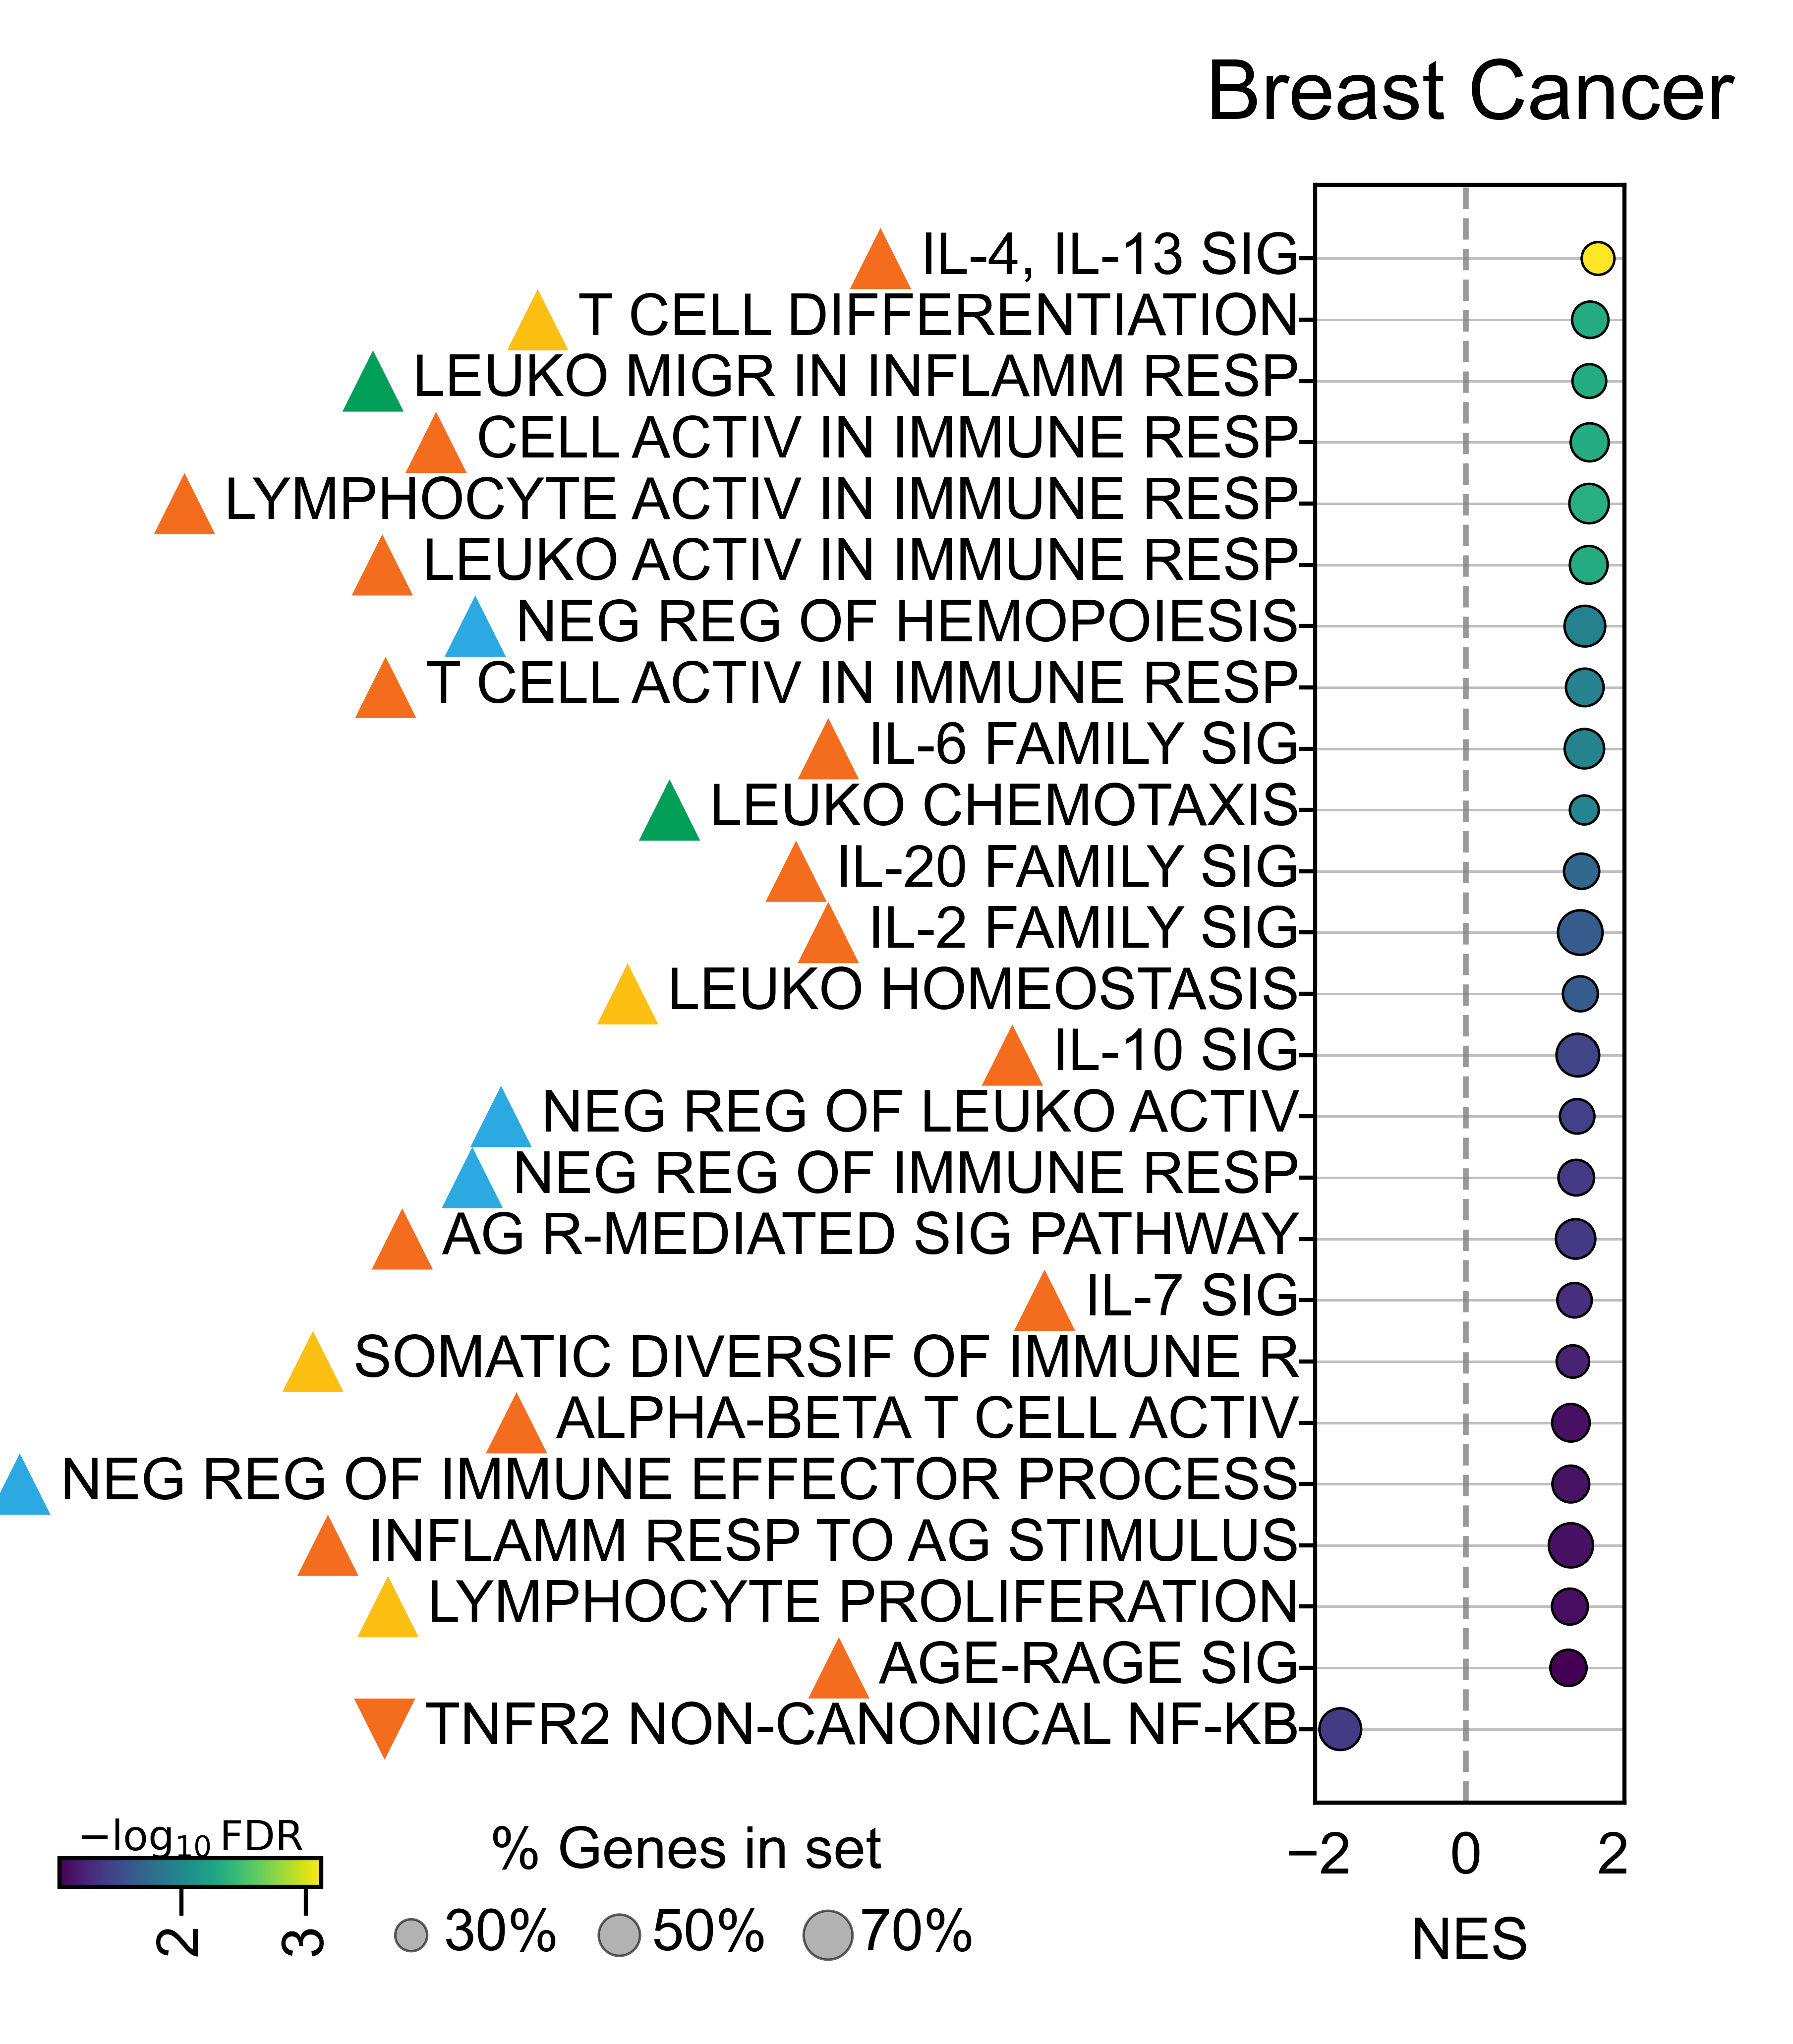

In [63]:
import pandas as pd
import matplotlib.pyplot as plt
from textwrap import fill
from matplotlib import font_manager as fm

title_map = {"HRL": "High-Risk Lesion", "DCIS": "DCIS", "BC": "Breast Cancer"}

# -----------------------------
# Prepare data
# -----------------------------
dfp2 = dfp[dfp["Term"].isin(paths_relevant)].copy()
dfp2["Term"] = pd.Categorical(dfp2["Term"], categories=paths_relevant, ordered=True)
dfp2 = dfp2.sort_values("Term").reset_index(drop=True)

dfp2["Term_full"] = dfp2["Term"].astype(str)
dfp2["Term_short"] = dfp2["Term_full"].map(short_name_map).fillna(dfp2["Term_full"])
dfp2["Term_plot"] = dfp2["Term_short"].apply(lambda x: fill(str(x), width=38))

# -----------------------------
# Parameters
# -----------------------------
dot_scale = 0.5
cmap = plt.cm.viridis
arial_font = fm.FontProperties(family="Arial")

label_fontsize = 7
label_right_x = -0.05

triangle_gap_px = 30
triangle_size = 55
triangle_half_width_px = 10

# -----------------------------
# Plot
# -----------------------------
fig, ax = plt.subplots(figsize=(2, 4))

# Main control:
# larger left = wider ylabel region + narrower bubble box
fig.subplots_adjust(left=0.72, right=0.98, bottom=0.24, top=0.92)

ypos = list(range(len(dfp2)))

sc = ax.scatter(
    dfp2["NES"],
    ypos,
    s=dfp2["Tag %"] * dot_scale,
    c=dfp2["log_p"],
    cmap=cmap,
    edgecolor="black",
    linewidth=0.3,
    zorder=3
)

# -----------------------------
# Manual y labels
# -----------------------------
ax.set_yticks(ypos)
ax.set_yticklabels([])
ax.invert_yaxis()

label_text_objects = []

for i, row in dfp2.iterrows():
    txt = ax.text(
        label_right_x,
        i,
        row["Term_plot"],
        transform=ax.get_yaxis_transform(),
        ha="right",
        va="center",
        fontsize=label_fontsize,
        clip_on=False
    )
    label_text_objects.append((txt, row["Term_full"], i))

# -----------------------------
# Axes formatting
# -----------------------------
nes_max = dfp2["NES"].abs().max()
nes_min = dfp2["NES"].min()
ax.set_xlim([nes_min * 1.2, nes_max * 1.2])

ax.set_xlabel("NES", fontsize=7)
ax.set_ylabel("")
ax.tick_params(axis="x", labelsize=7)
ax.tick_params(axis="y", length=2, labelsize=6, pad=1)
ax.set_title(title_map.get(DzState, DzState), fontsize=10, pad=8)

ax.grid(axis="y", linestyle="-", linewidth=0.3, color="gray", alpha=0.5, zorder=0)
ax.axvline(x=0, linestyle="--", linewidth=0.7, color="gray", alpha=0.8, zorder=1)

# -----------------------------
# Draw once, then measure manual labels
# -----------------------------
fig.canvas.draw()
renderer = fig.canvas.get_renderer()

label_bboxes = [
    txt.get_window_extent(renderer=renderer)
    for txt, term_full, i in label_text_objects
]

leftmost_label_x_display = min(b.x0 for b in label_bboxes)
lowest_label_y_display = min(b.y0 for b in label_bboxes)

leftmost_label_x_fig, lowest_label_y_fig = fig.transFigure.inverted().transform(
    (leftmost_label_x_display, lowest_label_y_display)
)

# -----------------------------
# Triangles immediately left of labels
# -----------------------------
for txt, term_full, i in label_text_objects:
    tri = triangle_map.get(term_full)
    if tri is None:
        continue

    bbox = txt.get_window_extent(renderer=renderer)
    triangle_x_display = bbox.x0 - triangle_gap_px - triangle_half_width_px
    triangle_x_axes = ax.transAxes.inverted().transform((triangle_x_display, bbox.y0))[0]

    ax.scatter(
        triangle_x_axes,
        i,
        marker=tri["marker"],
        s=triangle_size,
        color=tri["color"],
        edgecolor="none",
        transform=ax.get_yaxis_transform(),
        clip_on=False,
        zorder=5
    )

# -----------------------------
# Colorbar: left aligned to leftmost ylabel
# -----------------------------
cbar_left = leftmost_label_x_fig
cbar_bottom = lowest_label_y_fig - 0.055
cbar_width = 0.22
cbar_height = 0.012

cax = fig.add_axes([cbar_left, cbar_bottom, cbar_width, cbar_height])

cbar = fig.colorbar(sc, cax=cax, orientation="horizontal")
cbar.set_label(
    r"$-\log_{10}\mathrm{FDR}$",
    fontproperties=arial_font,
    fontsize=5,
    labelpad=1
)
cbar.ax.xaxis.set_label_position("top")
cbar.ax.xaxis.set_ticks_position("bottom")
cbar.ax.tick_params(labelsize=7, pad=1, rotation=90)
cbar.solids.set_rasterized(True)

# -----------------------------
# Bubble legend: right of colorbar
# -----------------------------
size_handles = [
    plt.scatter(
        [], [],
        s=size * dot_scale,
        c="gray",
        alpha=0.6,
        edgecolor="black",
        linewidth=0.3
    )
    for size in [30, 50, 70]
]

bubble_legend_x = cbar_left + cbar_width * 1.2
bubble_legend_y = cbar_bottom - 0.003

leg = fig.legend(
    size_handles,
    ["30%", "50%", "70%"],
    title="% Genes in set",
    title_fontsize=7,
    fontsize=7,
    frameon=False,
    loc="center left",
    bbox_to_anchor=(bubble_legend_x, bubble_legend_y),
    ncol=3,
    columnspacing=0.8,
    handletextpad=0.3,
    borderaxespad=0
)

# -----------------------------
# Save
# -----------------------------
plt.savefig(
    f"plots/F6/Bubble_CD4T_{DzState}.png",
    bbox_inches="tight",
    pad_inches=0.2, 
    dpi=600
)

plt.show()

### Overlap

In [9]:
t1 = {

# 'B CELL DIFFERENTIATION', 
# 'MONONUCLEAR CELL MIGRATION',
# 'NATURAL KILLER CELL ACTIVATION', 
'LEUKOCYTE CHEMOTAXIS',
# 'B CELL ACTIVATION', 
    'T CELL DIFFERENTIATION',
'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
# 'NATURAL KILLER CELL DIFFERENTIATION',
'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
# 'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS',
'LEUKOCYTE HOMEOSTASIS', 
    'INTERLEUKIN-2 FAMILY SIGNALING',
'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
# 'MYELOID LEUKOCYTE MIGRATION', 
    'ALPHA-BETA T CELL ACTIVATION',
'COSTIMULATION BY THE CD28 FAMILY', 
    'T CELL PROLIFERATION',
'T CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
# 'CLASS I MHC MEDIATED ANTIGEN PROCESSING & PRESENTATION',
# 'ACTIVATION OF INNATE IMMUNE RESPONSE', 
    'INTERLEUKIN-10 SIGNALING',
'RAP1 SIGNALLING', 
    'NEGATIVE REGULATION OF IMMUNE RESPONSE',
# 'STIMULATORY C-TYPE LECTIN RECEPTOR SIGNALING PATHWAY',
'INTERLEUKIN-20 FAMILY SIGNALING',
'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY',
'NEGATIVE REGULATION OF CYTOPLASMIC PATTERN RECOGNITION RECEPTOR SIGNALING PATHWAY',
'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 2 SIGNALING PATHWAY',
# 'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING',
'INTERLEUKIN-12 FAMILY SIGNALING', 
    'LYMPHOCYTE PROLIFERATION',
'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE',
'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION',
# 'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 4 SIGNALING PATHWAY',
'LEUKOCYTE MEDIATED CYTOTOXICITY', 
    'TOLERANCE INDUCTION',
# 'DAP12 INTERACTIONS',
'NEGATIVE REGULATION OF IMMUNE EFFECTOR PROCESS',
# 'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY',
# 'NATURAL KILLER CELL MEDIATED CYTOTOXICITY',
'INTERFERON GAMMA SIGNALING',
'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL',
'TCR SIGNALING',
'NEGATIVE REGULATION OF ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
'INTERLEUKIN-6 FAMILY SIGNALING',
# 'NATURAL KILLER CELL MEDIATED IMMUNITY',
# 'PROLACTIN RECEPTOR SIGNALING',
'ADVANCED GLYCOSYLATION ENDPRODUCT RECEPTOR SIGNALING',
# 'NEUTROPHIL DEGRANULATION', 
    'T CELL SELECTION',
# 'SIGNALING BY THE B CELL RECEPTOR (BCR)',
'INTERLEUKIN-1 FAMILY SIGNALING',
# 'ANTIGEN PROCESSING AND PRESENTATION',
'LEUKOCYTE MEDIATED IMMUNITY', 
    'FLT3 SIGNALING',
'SOMATIC DIVERSIFICATION OF IMMUNE RECEPTORS',
'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING',
'CELLULAR EXTRAVASATION', 
#     'ANTIMICROBIAL PEPTIDES',
# 'INNATE IMMUNE RESPONSE IN MUCOSA'    

}

t2 = {

'NEGATIVE REGULATION OF HEMOPOIESIS',
'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING',
'INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS',
# 'B CELL DIFFERENTIATION',
# 'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
'T CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
# 'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 4 SIGNALING PATHWAY',
# 'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
# 'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION',
'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
# 'B CELL ACTIVATION', 
'INTERLEUKIN-6 FAMILY SIGNALING',
'T CELL DIFFERENTIATION',
'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
'ALPHA-BETA T CELL ACTIVATION',
# 'STIMULATORY C-TYPE LECTIN RECEPTOR SIGNALING PATHWAY',
# 'NATURAL KILLER CELL ACTIVATION',
'INTERLEUKIN-20 FAMILY SIGNALING',
'INTERLEUKIN-2 FAMILY SIGNALING',
'COSTIMULATION BY THE CD28 FAMILY',
# 'NATURAL KILLER CELL DIFFERENTIATION',
# 'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 2 SIGNALING PATHWAY',
# 'DDX58/IFIH1-MEDIATED INDUCTION OF INTERFERON-ALPHA/BETA',
'SOMATIC DIVERSIFICATION OF IMMUNE RECEPTORS',
# 'ACTIVATION OF INNATE IMMUNE RESPONSE', 
'TOLERANCE INDUCTION',
'LEUKOCYTE HOMEOSTASIS', 
# 'TOLL-LIKE RECEPTOR CASCADES',
# 'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY',
'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING',
'INTERFERON ALPHA/BETA SIGNALING',
'ROS AND RNS PRODUCTION IN PHAGOCYTES',
'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',
'T CELL MEDIATED CYTOTOXICITY',
'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL',
'TNFR2 NON-CANONICAL NF-KB PATHWAY',
# 'ANTIMICROBIAL HUMORAL RESPONSE',
# 'INNATE IMMUNE RESPONSE IN MUCOSA'    

}

t3 = {

# 'B CELL DIFFERENTIATION', 'B CELL ACTIVATION',
       'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING',
       # 'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY',
       # 'ACTIVATION OF INNATE IMMUNE RESPONSE',
       # 'STIMULATORY C-TYPE LECTIN RECEPTOR SIGNALING PATHWAY',
       # 'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
       # 'ANTIMICROBIAL PEPTIDES', 'MONONUCLEAR CELL MIGRATION',
       'T CELL DIFFERENTIATION',
       'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE',
       'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       # 'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY',
       # 'MYELOID LEUKOCYTE ACTIVATION',
       # 'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       # 'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'NEGATIVE REGULATION OF HEMOPOIESIS',
       'T CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'INTERLEUKIN-6 FAMILY SIGNALING', 
    # 'MYELOID LEUKOCYTE MIGRATION',
       'LEUKOCYTE CHEMOTAXIS',
       # 'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 2 SIGNALING PATHWAY',
       'INTERLEUKIN-20 FAMILY SIGNALING',
       'INTERLEUKIN-2 FAMILY SIGNALING', 
    'LEUKOCYTE HOMEOSTASIS',
       # 'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 4 SIGNALING PATHWAY',
       'INTERLEUKIN-10 SIGNALING',
       'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION',
       # 'NATURAL KILLER CELL DIFFERENTIATION',
       # 'TOLL-LIKE RECEPTOR CASCADES',
       'NEGATIVE REGULATION OF IMMUNE RESPONSE',
       # 'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS',
       'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
       'INTERLEUKIN-7 SIGNALING', 
    # 'NATURAL KILLER CELL ACTIVATION',
       'SOMATIC DIVERSIFICATION OF IMMUNE RECEPTORS',
       'ALPHA-BETA T CELL ACTIVATION',
       'NEGATIVE REGULATION OF IMMUNE EFFECTOR PROCESS',
       'INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS',
       # 'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING',
       'LYMPHOCYTE PROLIFERATION',
       'ADVANCED GLYCOSYLATION ENDPRODUCT RECEPTOR SIGNALING',
       # 'GERMINAL CENTER FORMATION',
       'COMPLEMENT RECEPTOR MEDIATED SIGNALING PATHWAY',
       'T CELL PROLIFERATION', 
    # 'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',
       'TNFR2 NON-CANONICAL NF-KB PATHWAY',
       # 'INNATE IMMUNE RESPONSE IN MUCOSA'    
    
}

In [11]:
def write_gmt(gdict, fpath):
    with open(fpath, 'w') as f:
        for key, val in gdict.items():
            f.write(f"{key}\t{key}\t{'\t'.join(val)}\n")
    print(f"finished writing {len(gdict)} gene sets to {fpath}")


In [12]:
db = read_gmt('data/11_genesets/immport_allgenelist.gmt')

db_sel = {x:db[x.lower()] for x in t1|t2|t3}

write_gmt(db_sel, 'data/cytoscape/CD4T_immport.gmt')

finished writing 49 gene sets to data/cytoscape/CD4T_immport.gmt


# IC expression

## Single patient RNA expression

In [8]:
pb = pd.read_csv(
    'data/06_pb/pb_donor_celltypelevel3_normalizedexpression.csv',
    index_col=0
)
pb

,Pool137-10_Naive B,Pool137-10_Mature B,Pool137-10_Memory B,Pool137-10_Plasmablast,Pool137-10_Naive CD4T,Pool137-10_Central Memory CD4T,Pool137-10_Cytotoxic CD4T,Pool137-10_Effector Memory CD4T,Pool137-10_Treg,Pool137-10_Naive CD8T,...,Pool138-9_cDC1,Pool138-9_cDC2,Pool138-9_pDC,Pool138-9_Classical Monocyte,Pool138-9_Intermediate Monocyte,Pool138-9_Nonclassical Monocyte,Pool138-9_Cytotoxic Monocyte,Pool138-9_CD56-dim NK,Pool138-9_CD56-bright NK,Pool138-9_Proliferating NK
AL627309.1,0.000000,0.000000,0.000000,0.00000,0.002494,0.001780,0.0,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.00000,0.002497,0.000000,0.011402,0.000000,0.000000,0.00000,0.000000
AL627309.5,0.000000,0.000000,0.077361,0.00000,0.002494,0.003557,0.0,0.000000,0.000000,0.010665,...,0.000000,0.000000,0.00000,0.027130,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
LINC01409,0.023602,0.166051,0.278939,0.15813,0.099723,0.070506,0.0,0.036173,0.100100,0.041994,...,0.235280,0.054113,0.03163,0.060628,0.089544,0.118800,0.000000,0.044699,0.11698,0.000000
LINC01128,0.154593,0.239765,0.000000,0.00000,0.086072,0.083702,0.0,0.071083,0.034492,0.052223,...,0.235280,0.021998,0.06229,0.029560,0.000000,0.000000,0.056439,0.128517,0.11698,0.200667
LINC00115,0.046661,0.044168,0.077361,0.00000,0.022222,0.022898,0.0,0.018250,0.034492,0.010665,...,0.124543,0.032818,0.06229,0.029560,0.023149,0.033824,0.000000,0.007590,0.00000,0.200667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AC104758.2,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.00000,0.002497,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
AC015660.3,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.00000,0.004988,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
ZG16,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
AP001434.1,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.00000,0.007472,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000


In [9]:
cols_sel = [x for x in pb.columns if x.lower().endswith('cd4t') or x.lower().endswith('treg')]
gene_list = ["PDCD1", "CTLA4", "LAG3", "HAVCR2", "PVR"]  # last 2 are TIM3, TIGIT


gex = pb.loc[gene_list,cols_sel]
gex

,Pool137-10_Naive CD4T,Pool137-10_Central Memory CD4T,Pool137-10_Cytotoxic CD4T,Pool137-10_Effector Memory CD4T,Pool137-10_Treg,Pool137-11_Naive CD4T,Pool137-11_Central Memory CD4T,Pool137-11_Cytotoxic CD4T,Pool137-11_Effector Memory CD4T,Pool137-11_Treg,...,Pool138-8_Naive CD4T,Pool138-8_Central Memory CD4T,Pool138-8_Cytotoxic CD4T,Pool138-8_Effector Memory CD4T,Pool138-8_Treg,Pool138-9_Naive CD4T,Pool138-9_Central Memory CD4T,Pool138-9_Cytotoxic CD4T,Pool138-9_Effector Memory CD4T,Pool138-9_Treg
PDCD1,0.002494,0.046985,0.000000,0.104816,0.000000,0.001275,0.075122,0.132835,0.160528,0.108090,...,0.013744,0.079235,0.221324,0.183826,0.088771,0.002224,0.046076,0.114895,0.157234,0.090768
CTLA4,0.236775,0.287570,0.000000,0.214651,1.408120,0.163292,0.375963,0.355003,0.251593,1.245076,...,0.144692,0.134795,0.116772,0.090386,0.964905,0.186344,0.173567,0.000000,0.152529,1.257865
LAG3,0.022222,0.052072,0.189199,0.286319,0.067834,0.035108,0.036387,0.449958,0.171066,0.000000,...,0.006895,0.038420,0.170414,0.146402,0.000000,0.024196,0.021948,0.114895,0.089268,0.000000
HAVCR2,0.019777,0.017660,0.189199,0.018250,0.000000,0.023957,0.015483,0.000000,0.000000,0.000000,...,0.027301,0.024437,0.000000,0.037140,0.000000,0.026367,0.015596,0.114895,0.021732,0.090768
PVR,0.007462,0.001780,0.000000,0.000000,0.000000,0.020212,0.001948,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.006287,0.000000,0.019840,0.004612,0.000000,0.000000,0.000000


In [10]:
df = gex.reset_index().rename(columns={'index': 'gene'})

# melt wide → long
df_long = (
    df
    .melt(id_vars='gene', var_name='sample', value_name='expr')
)

# split sample into dataset_name + celltype
df_long[['dataset_name', 'celltype']] = df_long['sample'].str.split('_', n=1, expand=True)

# rearrange columns
df_long = df_long[['gene', 'dataset_name', 'celltype', 'expr']]

df_long['dataset_name'] = [x.replace('-','_') for x in df_long['dataset_name']]
df_long.head(3)

,gene,dataset_name,celltype,expr
0,PDCD1,Pool137_10,Naive CD4T,0.002494
1,CTLA4,Pool137_10,Naive CD4T,0.236775
2,LAG3,Pool137_10,Naive CD4T,0.022222


In [13]:
meta = pd.read_csv('data/01_meta/meta_pt.csv', index_col=0)
#meta.index = [x.replace('_','-') for x in meta.index]

meta['race-stage'] = meta['race'].astype(str) + '-' + meta['group'].astype(str)

meta['race-stage'] = pd.Categorical(
    meta['race-stage'],
    categories=['NHW-HRL', 'NHW-DCIS', 'NHW-BC','NHB-HRL', 'NHB-DCIS', 'NHB-BC'],
    ordered=True
    )

meta

,dataset_name,batch,viability_pct,group,race,age,diabetes,obesity,race-stage
sampleid,,,,,,,,,
9-D,Pool137_7,1,95,DCIS,NHW,37.0,N,N,NHW-DCIS
30-D,Pool137_12,1,92,DCIS,NHW,78.0,N,N,NHW-DCIS
36-D,Pool137_18,1,93,DCIS,NHB,39.0,N,N,NHB-DCIS
119-D,Pool137_20,1,95,DCIS,NHB,80.0,N,N,NHB-DCIS
28-D,Pool137_24,1,94,DCIS,NHW,53.0,N,N,NHW-DCIS
53-D,Pool137_27,1,96,DCIS,NHB,45.0,N,N,NHB-DCIS
77-D,Pool137_30,1,90,DCIS,NHW,45.0,N,N,NHW-DCIS
31-D,Pool138_6,2,93,DCIS,NHW,44.0,N,N,NHW-DCIS
6-H,Pool137_6,1,94,HRL,NHW,71.1,N,Y,NHW-HRL


In [33]:
meta.groupby(['group','race']).size().unstack()

race,NHB,NHW
group,,
BC,13,12
DCIS,4,6
HRL,10,10


In [14]:
dfp = pd.merge(meta, df_long, on='dataset_name')
dfp

,dataset_name,batch,viability_pct,group,race,age,diabetes,obesity,race-stage,gene,celltype,expr
0,Pool137_7,1,95,DCIS,NHW,37.0,N,N,NHW-DCIS,PDCD1,Naive CD4T,0.002821
1,Pool137_7,1,95,DCIS,NHW,37.0,N,N,NHW-DCIS,CTLA4,Naive CD4T,0.086552
2,Pool137_7,1,95,DCIS,NHW,37.0,N,N,NHW-DCIS,LAG3,Naive CD4T,0.011238
3,Pool137_7,1,95,DCIS,NHW,37.0,N,N,NHW-DCIS,HAVCR2,Naive CD4T,0.030605
4,Pool137_7,1,95,DCIS,NHW,37.0,N,N,NHW-DCIS,PVR,Naive CD4T,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...
1370,Pool138_26,2,94,BC,NHB,86.0,Y,Y,NHB-BC,PDCD1,Treg,0.092382
1371,Pool138_26,2,94,BC,NHB,86.0,Y,Y,NHB-BC,CTLA4,Treg,1.020426
1372,Pool138_26,2,94,BC,NHB,86.0,Y,Y,NHB-BC,LAG3,Treg,0.062527
1373,Pool138_26,2,94,BC,NHB,86.0,Y,Y,NHB-BC,HAVCR2,Treg,0.149546


In [15]:
Counter(dfp['celltype'])

Counter({'Naive CD4T': 275,
         'Central Memory CD4T': 275,
         'Cytotoxic CD4T': 275,
         'Effector Memory CD4T': 275,
         'Treg': 275})

/tmp/ipykernel_259811/2843809975.py:77: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfp_sub[xname] = pd.Categorical(
/tmp/ipykernel_259811/2843809975.py:87: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_stats = dfp_sub.groupby(xname)['expr'].median()#.sort_values(ascending=False)



PDCD1 Naive CD4T
race
NHW    0.003994
NHB    0.001005
Name: expr, dtype: float64
NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided, P_val:4.286e-03 U_stat=8.800e+01


/tmp/ipykernel_259811/2843809975.py:77: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfp_sub[xname] = pd.Categorical(
/tmp/ipykernel_259811/2843809975.py:87: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_stats = dfp_sub.groupby(xname)['expr'].median()#.sort_values(ascending=False)



CTLA4 Naive CD4T
race
NHW    0.236053
NHB    0.296277
Name: expr, dtype: float64
NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided, P_val:8.897e-02 U_stat=2.700e+01


/tmp/ipykernel_259811/2843809975.py:77: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfp_sub[xname] = pd.Categorical(
/tmp/ipykernel_259811/2843809975.py:87: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_stats = dfp_sub.groupby(xname)['expr'].median()#.sort_values(ascending=False)


...


CTLA4 Treg
race
NHW    1.205062
NHB    1.205032
Name: expr, dtype: float64
NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided, P_val:9.097e-01 U_stat=5.200e+01


/tmp/ipykernel_259811/2843809975.py:77: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfp_sub[xname] = pd.Categorical(
/tmp/ipykernel_259811/2843809975.py:87: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_stats = dfp_sub.groupby(xname)['expr'].median()#.sort_values(ascending=False)



HAVCR2 Treg
race
NHW    0.027849
NHB    0.043187
Name: expr, dtype: float64
NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided, P_val:6.771e-01 U_stat=4.400e+01


/tmp/ipykernel_259811/2843809975.py:77: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfp_sub[xname] = pd.Categorical(
/tmp/ipykernel_259811/2843809975.py:87: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_stats = dfp_sub.groupby(xname)['expr'].median()#.sort_values(ascending=False)



LAG3 Treg
race
NHW    0.019827
NHB    0.028438
Name: expr, dtype: float64
NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided, P_val:8.469e-01 U_stat=4.700e+01


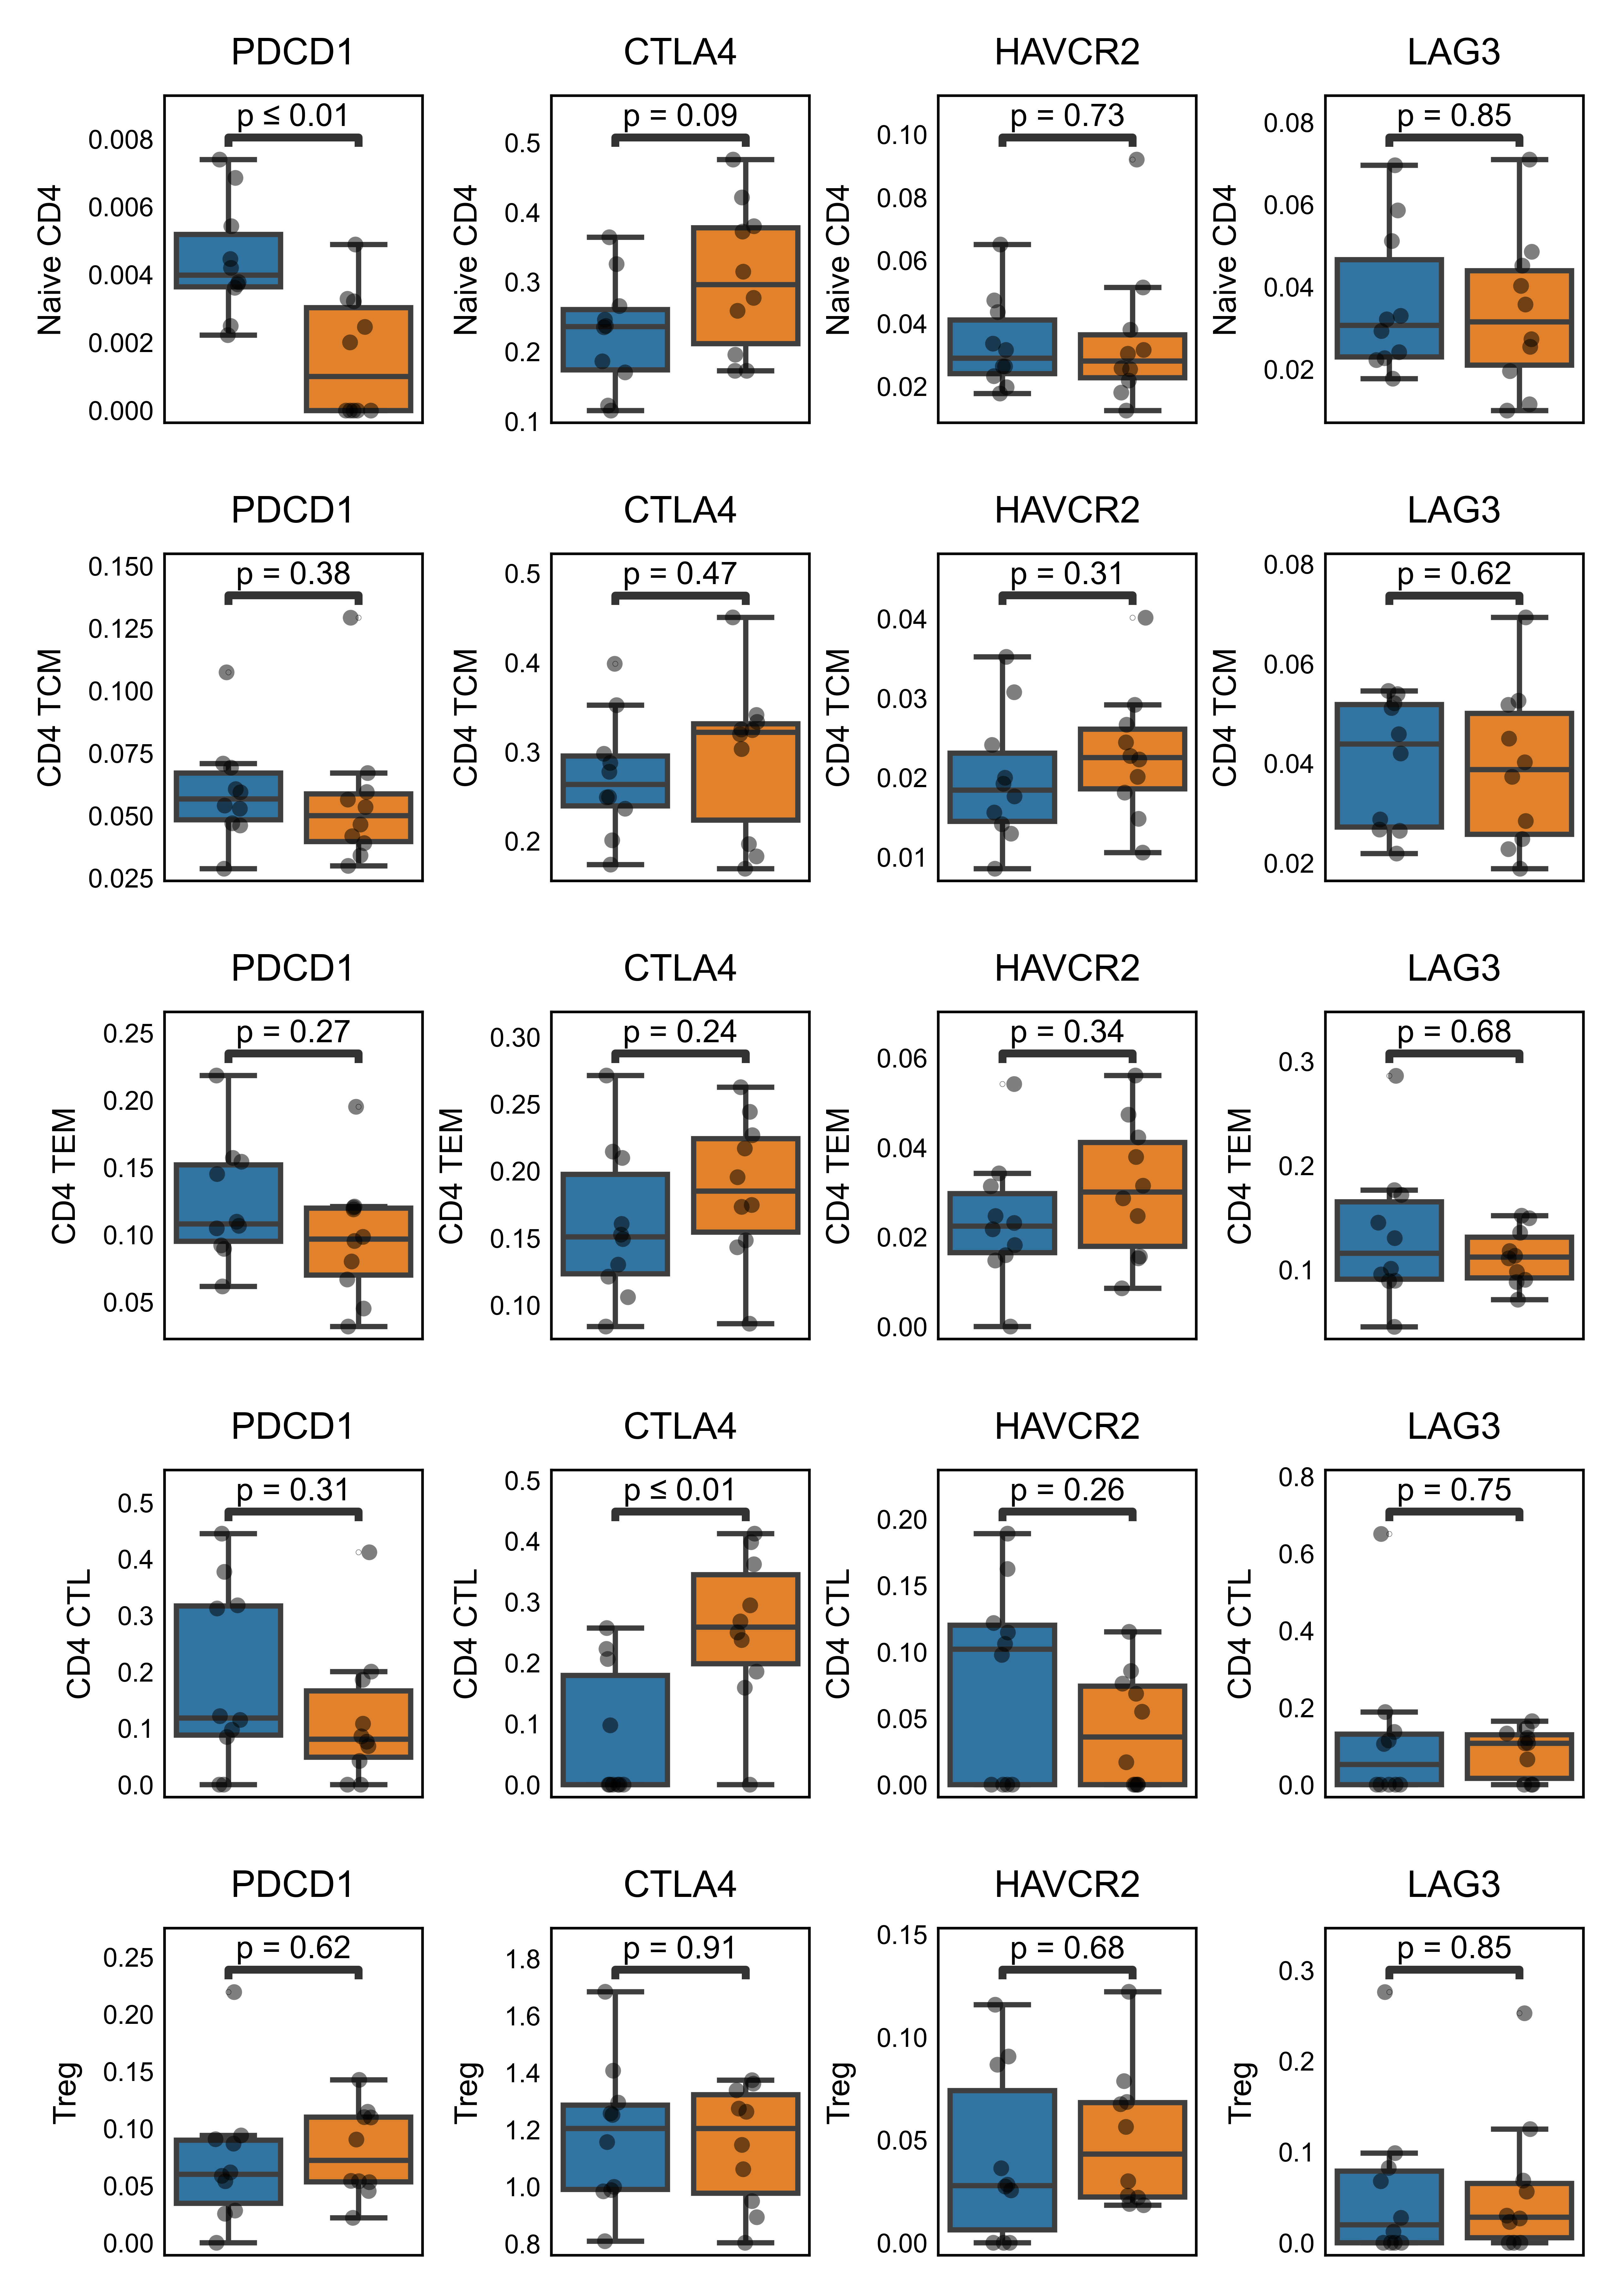

In [32]:
# HRL
from statannotations.Annotator import Annotator


newlabel_dict = {
'Naive CD4T': 'Naive CD4', 
'Central Memory CD4T': 'CD4 TCM', 
'Effector Memory CD4T': 'CD4 TEM', 
'Cytotoxic CD4T': 'CD4 CTL',
'Treg':'Treg'
}


celltypes = [
    'Naive CD4T',
  'Central Memory CD4T',
  'Effector Memory CD4T',
  'Cytotoxic CD4T',
  'Treg']

ynames = [
"PDCD1", "CTLA4", "HAVCR2", "LAG3", #, "PVR"
]

xname = 'race'


fig, axs = plt.subplots(figsize=(1.2 * 4, 1.5 * 5), 
                    ncols=4, nrows=5, 
                    sharex=True, sharey=False)

fig.subplots_adjust(wspace=0.5, hspace=.4
                   )
ct = -1
for celltype in celltypes:
   
    for yname in ynames:

        dfp_sub = dfp[
            (dfp['group']=='HRL') &
            (dfp['celltype']==celltype) & 
            (dfp['gene']==yname)]
        ct += 1
            
        ax = axs.flatten()[ct]  
    
                
        sns.boxplot(
            data=dfp_sub,
            x=xname,
            y='expr',
            hue=xname,
            # palette=color_set,
            flierprops=dict(marker='o', markersize=.1, alpha=0.7),
            ax=ax,
            showfliers=True
        ).set_rasterized(True)  
        
        sns.stripplot(
            data=dfp_sub, x=xname, y='expr', size=3, color='black', alpha=.5, ax=ax
        ).set_rasterized(True)  


        dfp_sub[xname] = pd.Categorical(
            dfp_sub[xname], 
            categories=[ 
            'NHW', 'NHB'], 
            ordered=True
        )
        
        pairs = [
            ('NHW', 'NHB')
        ]
        group_stats = dfp_sub.groupby(xname)['expr'].median()#.sort_values(ascending=False)
        print(f"\n{yname} {celltype}")
        print(group_stats)

        annotator = Annotator(
            ax, pairs, data=dfp_sub, x=xname, y='expr', perform_stat_test=True
        )
        
        annotator.configure(test='Mann-Whitney',
                            text_format='simple', 
                            loc='inside', 
                            show_test_name = False,
                            hide_non_significant=False) # but I already set new p values from scanpro
        annotator.apply_and_annotate()
        
        ax.set_title(yname)
        ax.set_xlabel('')


        ax.set_ylabel(newlabel_dict[celltype], fontsize=6)  # Hide to save space


        ax.set_xticklabels('')
        ax.tick_params(axis='x', labelsize=4, rotation=90, pad=-1)
        for label in ax.get_xticklabels():
            label.set_ha('right')
        ax.tick_params(axis='y', labelsize=5, pad=2, length=0)
        ax.tick_params(axis='x', labelsize=6, pad=0, length=0)
        ax.legend([],[], frameon=False)  # Remove legend
        

/tmp/ipykernel_259811/565399845.py:77: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfp_sub[xname] = pd.Categorical(
/tmp/ipykernel_259811/565399845.py:87: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_stats = dfp_sub.groupby(xname)['expr'].median()#.sort_values(ascending=False)



PDCD1 Naive CD4T
race
NHW    0.001411
NHB    0.000000
Name: expr, dtype: float64
NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided, P_val:4.712e-01 U_stat=1.550e+01


/tmp/ipykernel_259811/565399845.py:77: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfp_sub[xname] = pd.Categorical(
/tmp/ipykernel_259811/565399845.py:87: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_stats = dfp_sub.groupby(xname)['expr'].median()#.sort_values(ascending=False)



CTLA4 Naive CD4T
race
NHW    0.120492
NHB    0.214558
Name: expr, dtype: float64
NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided, P_val:3.524e-01 U_stat=7.000e+00


/tmp/ipykernel_259811/565399845.py:77: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfp_sub[xname] = pd.Categorical(
/tmp/ipykernel_259811/565399845.py:87: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_stats = dfp_sub.groupby(xname)['expr'].median()#.sort_values(ascending=False)


...


CTLA4 Treg
race
NHW    1.075736
NHB    0.967655
Name: expr, dtype: float64
NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided, P_val:7.619e-01 U_stat=1.400e+01


/tmp/ipykernel_259811/565399845.py:77: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfp_sub[xname] = pd.Categorical(
/tmp/ipykernel_259811/565399845.py:87: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_stats = dfp_sub.groupby(xname)['expr'].median()#.sort_values(ascending=False)



HAVCR2 Treg
race
NHW    0.070491
NHB    0.020083
Name: expr, dtype: float64
NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided, P_val:1.905e-02 U_stat=2.300e+01


/tmp/ipykernel_259811/565399845.py:77: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfp_sub[xname] = pd.Categorical(
/tmp/ipykernel_259811/565399845.py:87: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_stats = dfp_sub.groupby(xname)['expr'].median()#.sort_values(ascending=False)



LAG3 Treg
race
NHW    0.008932
NHB    0.000000
Name: expr, dtype: float64
NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided, P_val:6.310e-01 U_stat=1.450e+01


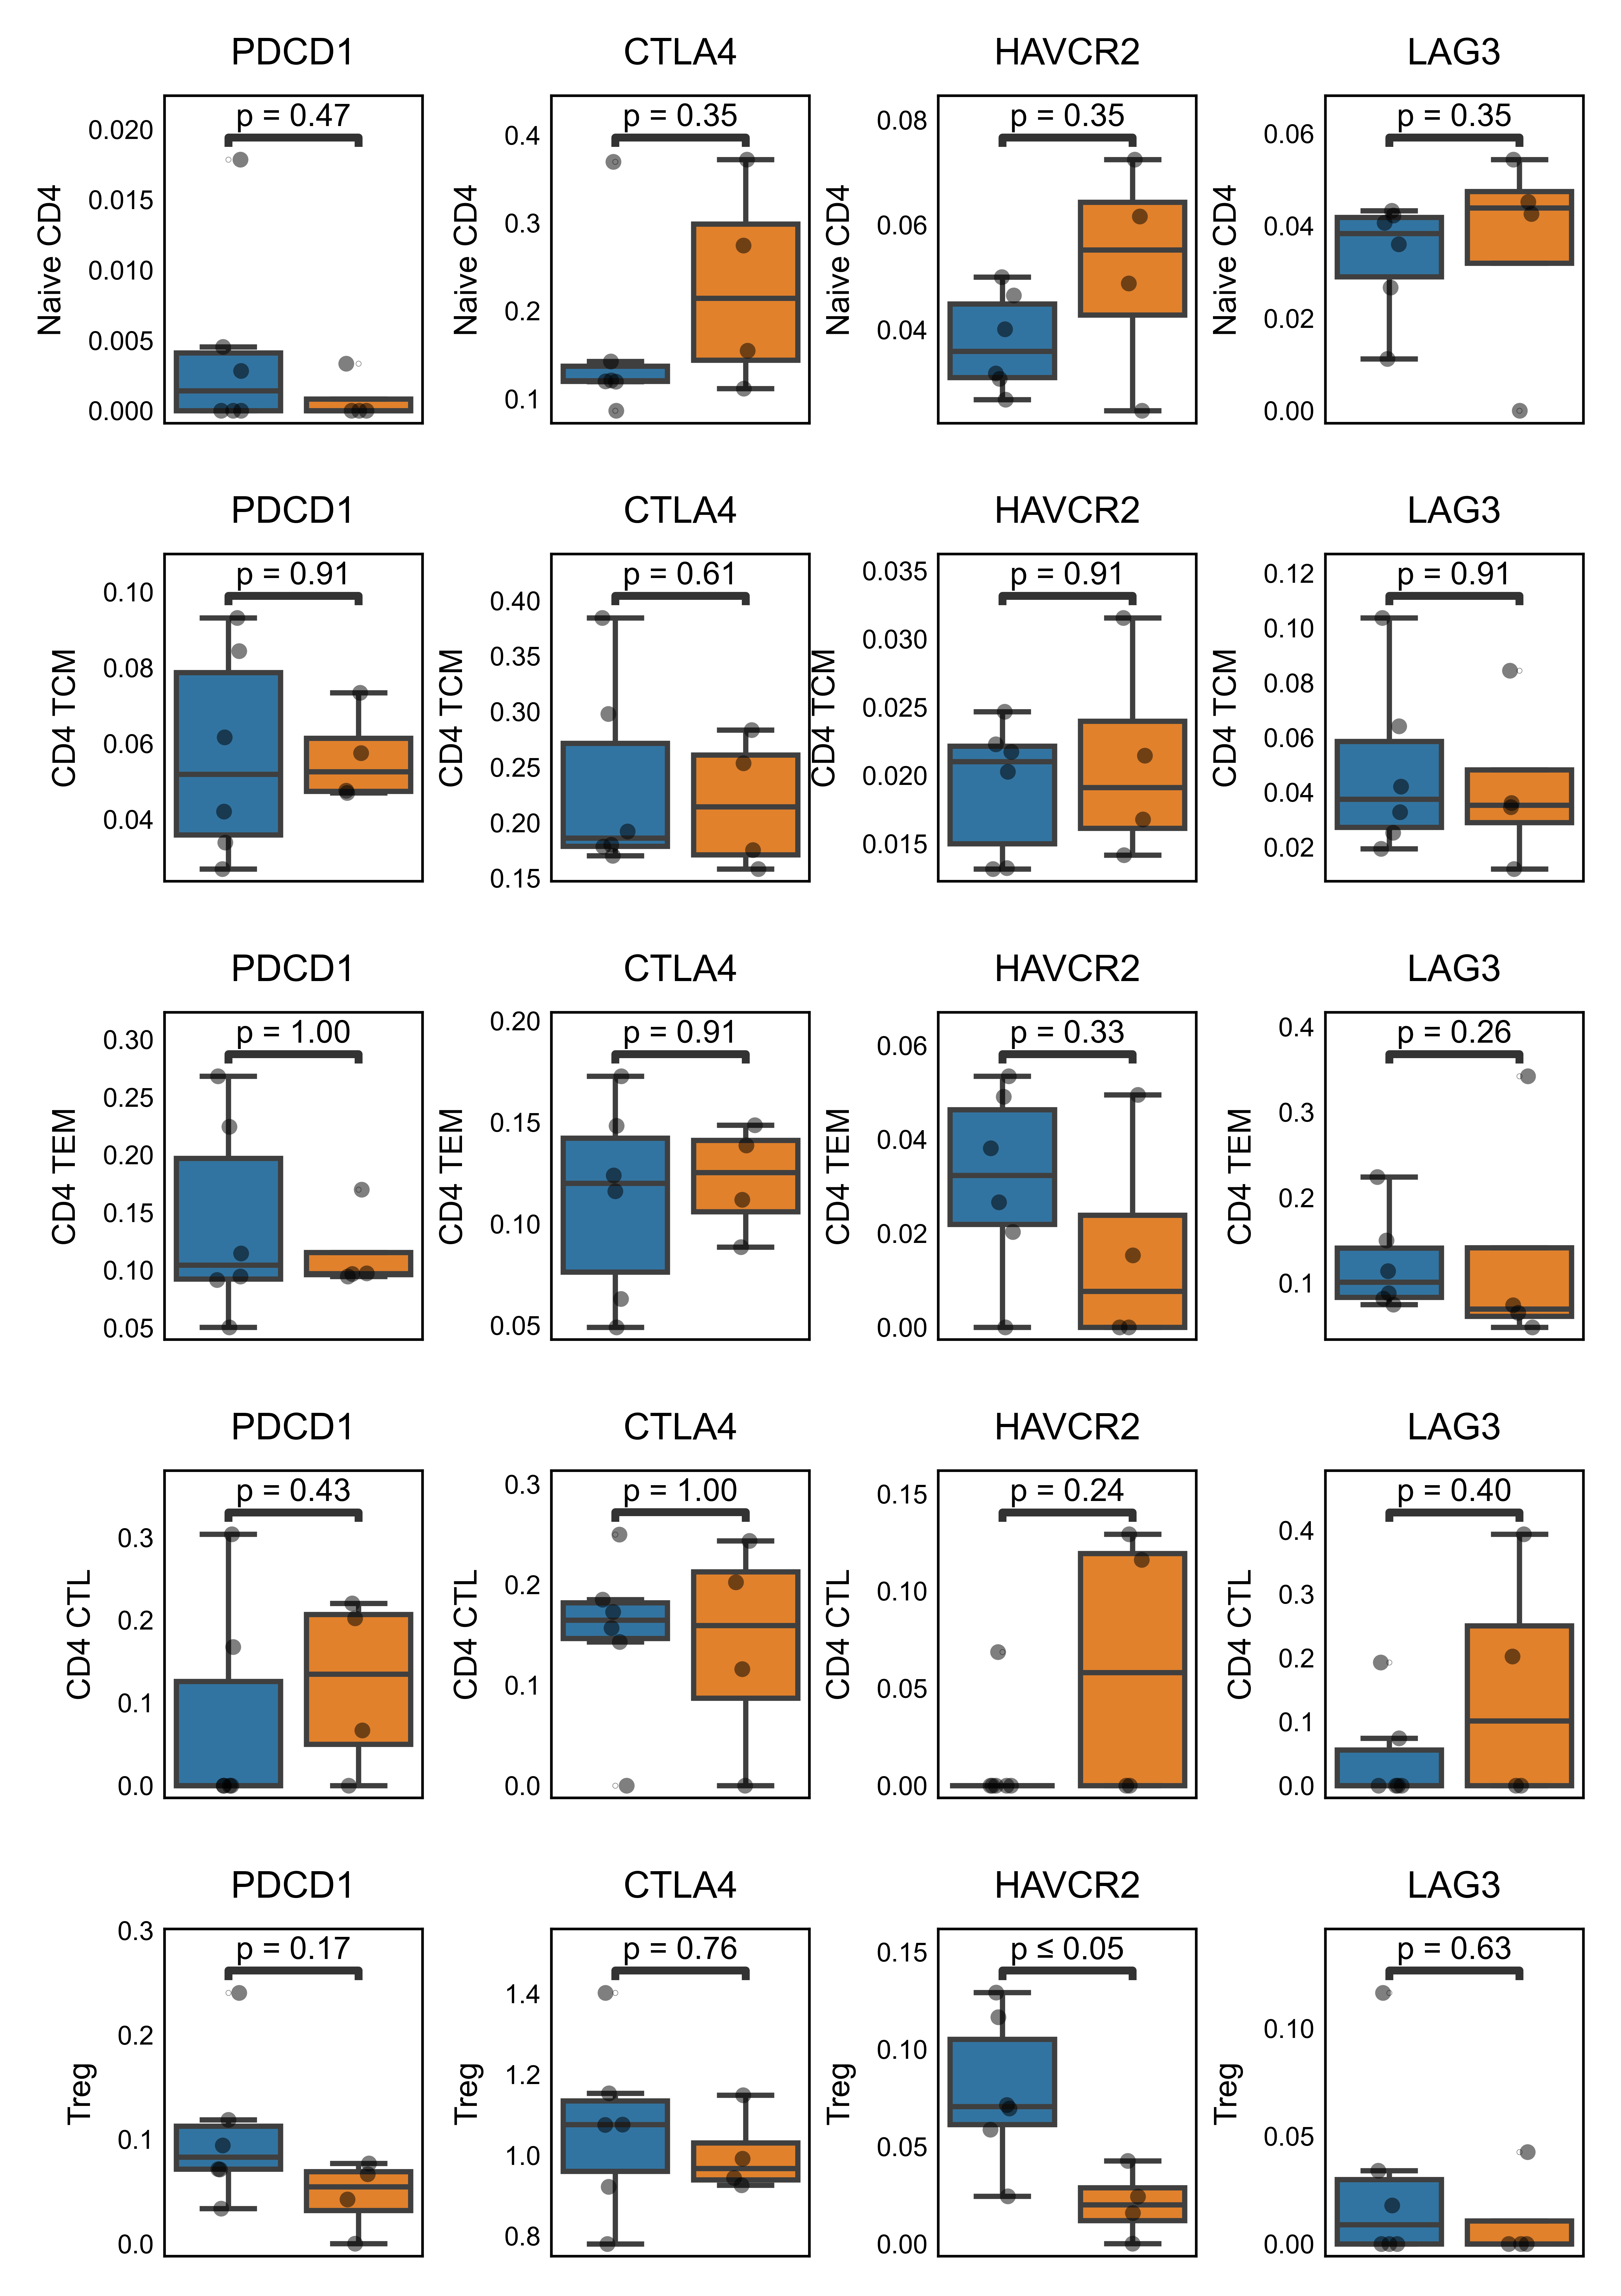

In [31]:
# DCIS
from statannotations.Annotator import Annotator


newlabel_dict = {
'Naive CD4T': 'Naive CD4', 
'Central Memory CD4T': 'CD4 TCM', 
'Effector Memory CD4T': 'CD4 TEM', 
'Cytotoxic CD4T': 'CD4 CTL',
'Treg':'Treg'
}


celltypes = [
    'Naive CD4T',
  'Central Memory CD4T',
  'Effector Memory CD4T',
  'Cytotoxic CD4T',
  'Treg']

ynames = [
"PDCD1", "CTLA4", "HAVCR2", "LAG3", #, "PVR"
]

xname = 'race'


fig, axs = plt.subplots(figsize=(1.2 * 4, 1.5 * 5), 
                    ncols=4, nrows=5, 
                    sharex=True, sharey=False)

fig.subplots_adjust(wspace=0.5, hspace=.4
                   )
ct = -1
for celltype in celltypes:
   
    for yname in ynames:

        dfp_sub = dfp[
            (dfp['group']=='DCIS') &
            (dfp['celltype']==celltype) & 
            (dfp['gene']==yname)]
        ct += 1
            
        ax = axs.flatten()[ct]  
    
                
        sns.boxplot(
            data=dfp_sub,
            x=xname,
            y='expr',
            hue=xname,
            # palette=color_set,
            flierprops=dict(marker='o', markersize=.1, alpha=0.7),
            ax=ax,
            showfliers=True
        ).set_rasterized(True)  
        
        sns.stripplot(
            data=dfp_sub, x=xname, y='expr', size=3, color='black', alpha=.5, ax=ax
        ).set_rasterized(True)  


        dfp_sub[xname] = pd.Categorical(
            dfp_sub[xname], 
            categories=[ 
            'NHW', 'NHB'], 
            ordered=True
        )
        
        pairs = [
            ('NHW', 'NHB')
        ]
        group_stats = dfp_sub.groupby(xname)['expr'].median()#.sort_values(ascending=False)
        print(f"\n{yname} {celltype}")
        print(group_stats)

        annotator = Annotator(
            ax, pairs, data=dfp_sub, x=xname, y='expr', perform_stat_test=True
        )
        
        annotator.configure(test='Mann-Whitney',
                            text_format='simple', 
                            loc='inside', 
                            show_test_name = False,
                            hide_non_significant=False) # but I already set new p values from scanpro
        annotator.apply_and_annotate()
        
        ax.set_title(yname)
        ax.set_xlabel('')


        ax.set_ylabel(newlabel_dict[celltype], fontsize=6)  # Hide to save space


        ax.set_xticklabels('')
        ax.tick_params(axis='x', labelsize=4, rotation=90, pad=-1)
        for label in ax.get_xticklabels():
            label.set_ha('right')
        ax.tick_params(axis='y', labelsize=5, pad=2, length=0)
        ax.tick_params(axis='x', labelsize=6, pad=0, length=0)
        ax.legend([],[], frameon=False)  # Remove legend
        

/tmp/ipykernel_259811/2651353620.py:76: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfp_sub[xname] = pd.Categorical(
/tmp/ipykernel_259811/2651353620.py:86: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_stats = dfp_sub.groupby(xname)['expr'].median()#.sort_values(ascending=False)



PDCD1 Naive CD4T
race
NHW    0.002694
NHB    0.004417
Name: expr, dtype: float64
NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided, P_val:8.053e-01 U_stat=7.300e+01


/tmp/ipykernel_259811/2651353620.py:76: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfp_sub[xname] = pd.Categorical(
/tmp/ipykernel_259811/2651353620.py:86: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_stats = dfp_sub.groupby(xname)['expr'].median()#.sort_values(ascending=False)



CTLA4 Naive CD4T
race
NHW    0.190810
NHB    0.257016
Name: expr, dtype: float64
NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided, P_val:2.012e-01 U_stat=5.400e+01


/tmp/ipykernel_259811/2651353620.py:76: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfp_sub[xname] = pd.Categorical(
/tmp/ipykernel_259811/2651353620.py:86: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_stats = dfp_sub.groupby(xname)['expr'].median()#.sort_values(ascending=False)


...


CTLA4 Treg
race
NHW    1.090252
NHB    1.138456
Name: expr, dtype: float64
NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided, P_val:9.350e-01 U_stat=7.600e+01


/tmp/ipykernel_259811/2651353620.py:76: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfp_sub[xname] = pd.Categorical(
/tmp/ipykernel_259811/2651353620.py:86: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_stats = dfp_sub.groupby(xname)['expr'].median()#.sort_values(ascending=False)



HAVCR2 Treg
race
NHW    0.039067
NHB    0.069351
Name: expr, dtype: float64
NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided, P_val:1.994e-01 U_stat=5.400e+01


/tmp/ipykernel_259811/2651353620.py:76: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfp_sub[xname] = pd.Categorical(
/tmp/ipykernel_259811/2651353620.py:86: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_stats = dfp_sub.groupby(xname)['expr'].median()#.sort_values(ascending=False)



LAG3 Treg
race
NHW    0.021385
NHB    0.018352
Name: expr, dtype: float64
NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided, P_val:9.105e-01 U_stat=8.050e+01


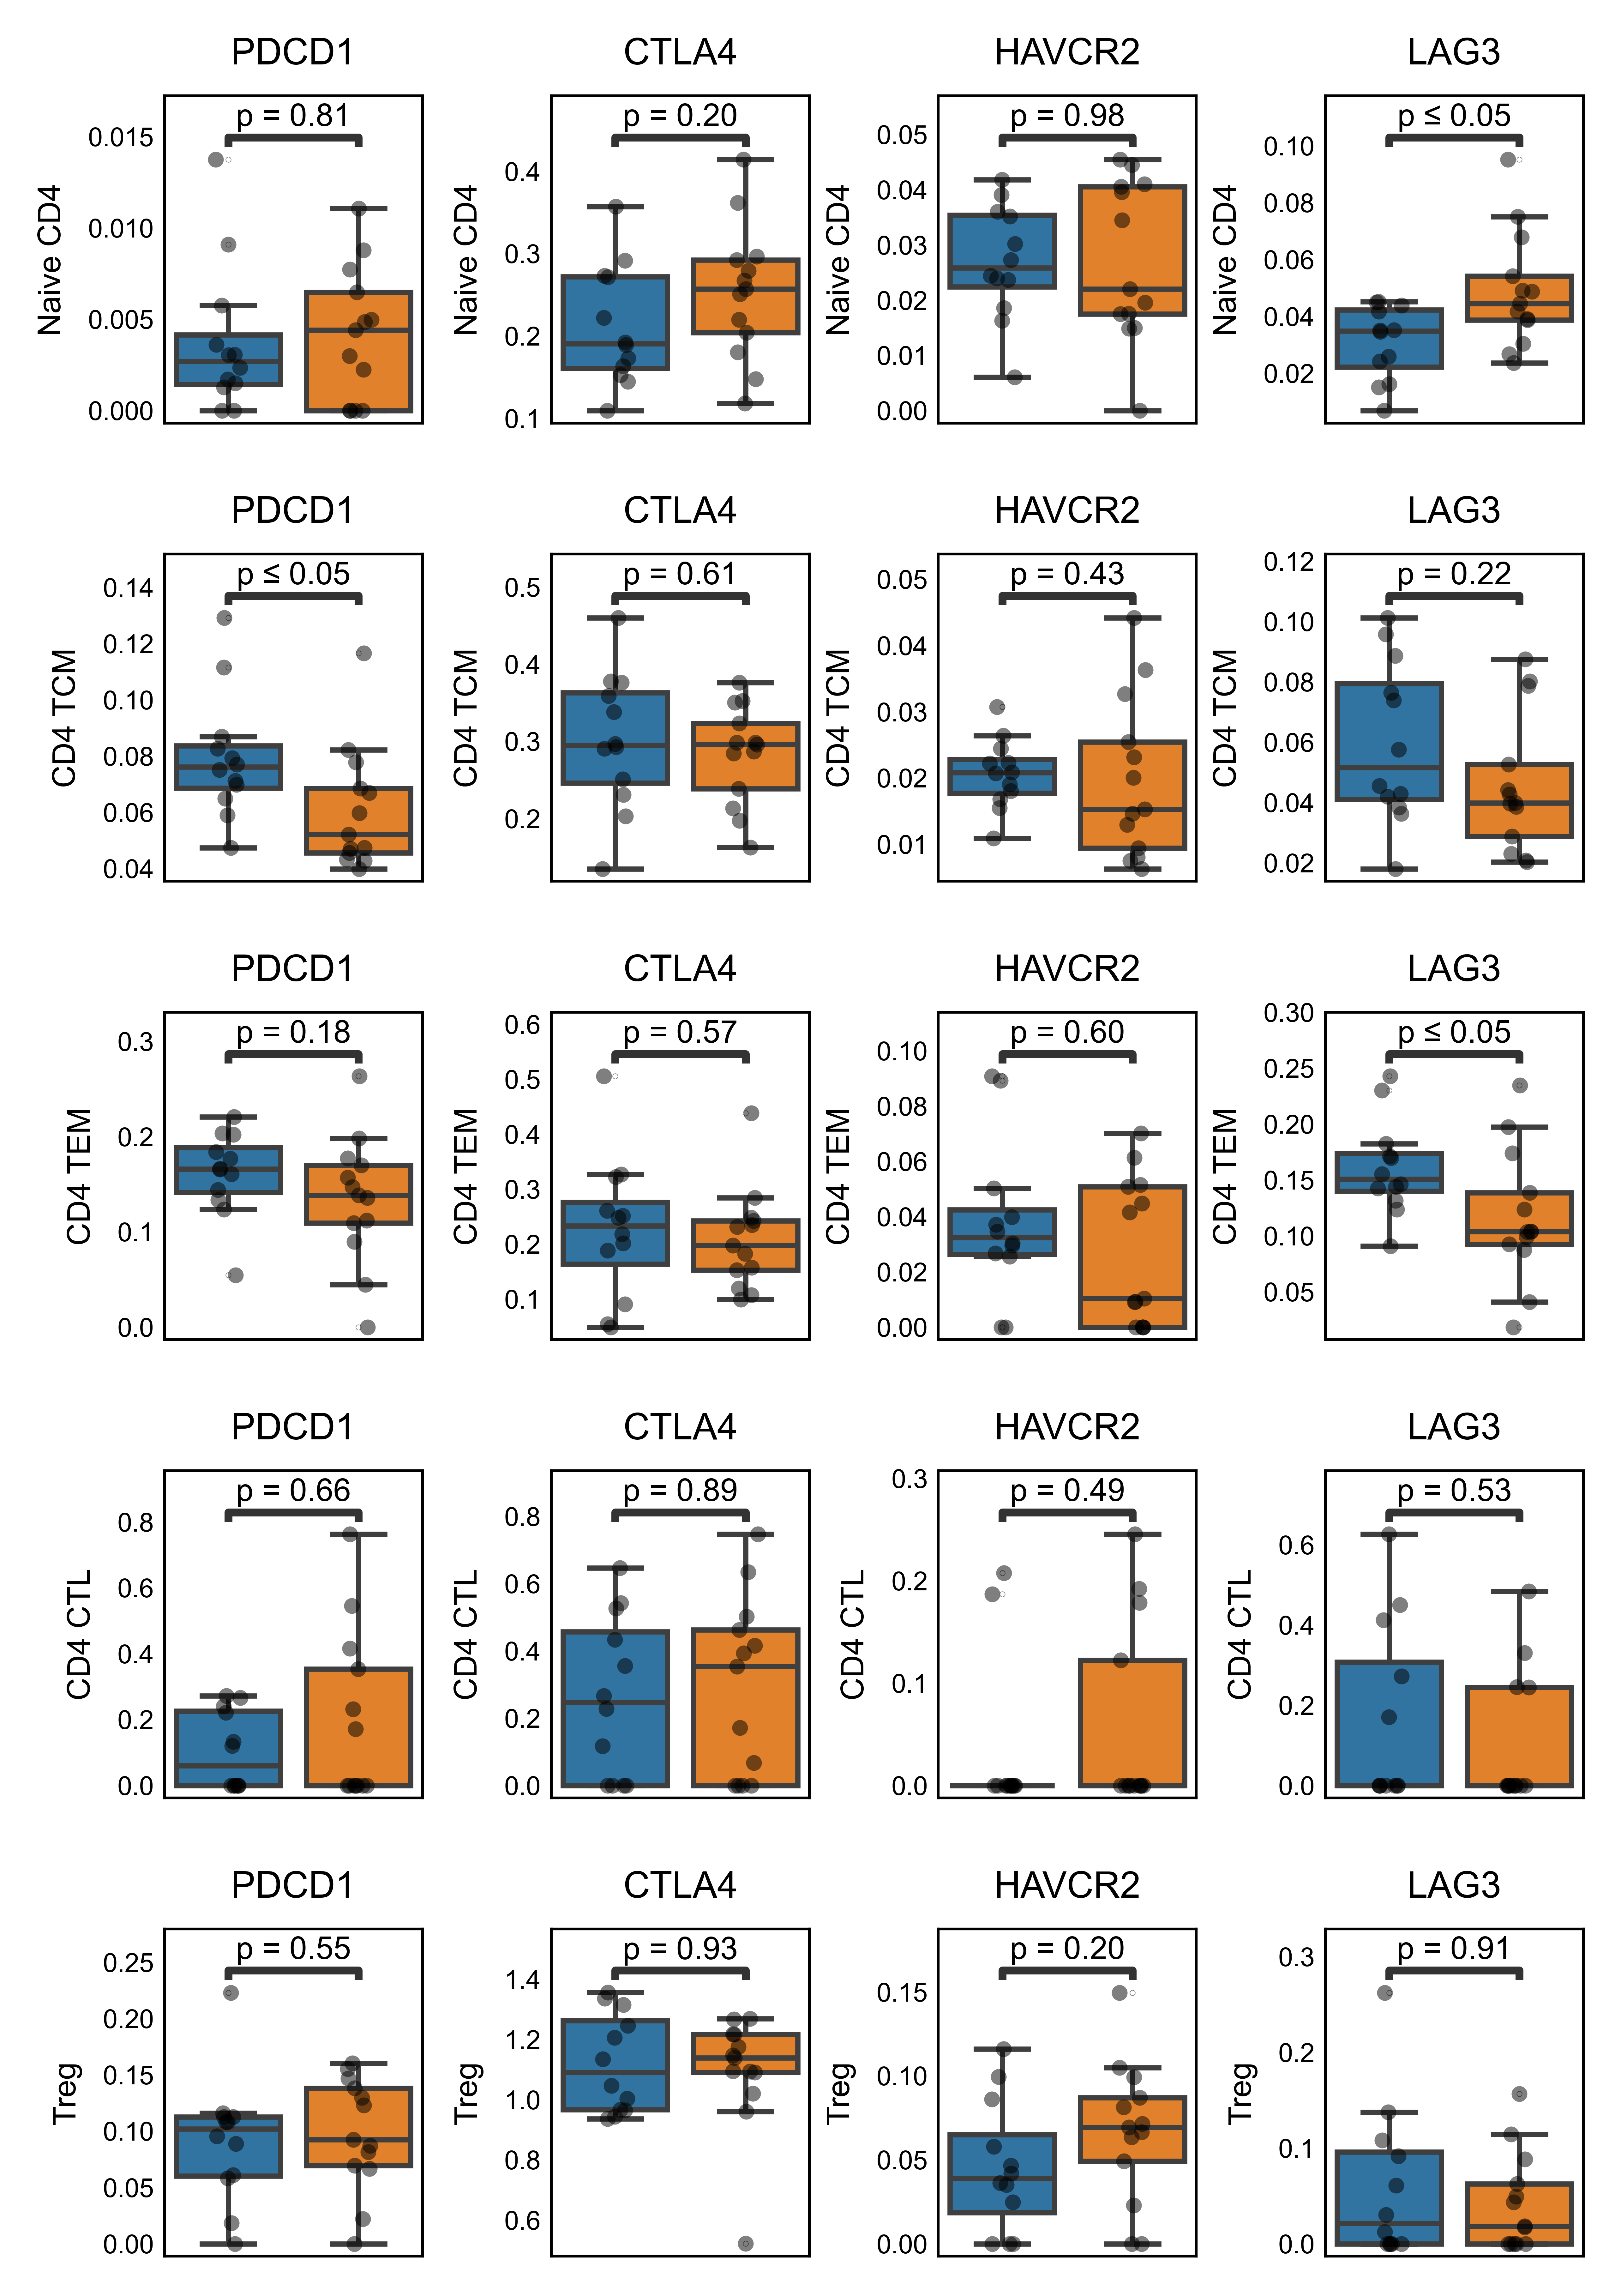

In [30]:
# BC
from statannotations.Annotator import Annotator


newlabel_dict = {
'Naive CD4T': 'Naive CD4', 
'Central Memory CD4T': 'CD4 TCM', 
'Effector Memory CD4T': 'CD4 TEM', 
'Cytotoxic CD4T': 'CD4 CTL',
'Treg':'Treg'
}


celltypes = [
    'Naive CD4T',
  'Central Memory CD4T',
  'Effector Memory CD4T',
  'Cytotoxic CD4T',
  'Treg']

ynames = [
"PDCD1", "CTLA4", "HAVCR2", "LAG3", #, "PVR"
]

xname = 'race'


fig, axs = plt.subplots(figsize=(1.2 * 4, 1.5 * 5), 
                    ncols=4, nrows=5, 
                    sharex=True, sharey=False)

fig.subplots_adjust(wspace=0.5, hspace=.4
                   )
ct = -1
for celltype in celltypes:
   
    for yname in ynames:

        dfp_sub = dfp[
            (dfp['group']=='BC') &
            (dfp['celltype']==celltype) & 
            (dfp['gene']==yname)]
        ct += 1
            
        ax = axs.flatten()[ct]  
    
                
        sns.boxplot(
            data=dfp_sub,
            x=xname,
            y='expr',
            hue=xname,
            # palette=color_set,
            flierprops=dict(marker='o', markersize=.1, alpha=0.7),
            ax=ax,
            showfliers=True
        ).set_rasterized(True)  
        
        sns.stripplot(
            data=dfp_sub, x=xname, y='expr', size=3, color='black', alpha=.5, ax=ax
        ).set_rasterized(True)  


        dfp_sub[xname] = pd.Categorical(
            dfp_sub[xname], 
            categories=[ 
            'NHW', 'NHB'], 
            ordered=True
        )
        
        pairs = [
            ('NHW', 'NHB')
        ]
        group_stats = dfp_sub.groupby(xname)['expr'].median()#.sort_values(ascending=False)
        print(f"\n{yname} {celltype}")
        print(group_stats)

        annotator = Annotator(
            ax, pairs, data=dfp_sub, x=xname, y='expr', perform_stat_test=True
        )
        
        annotator.configure(test='Mann-Whitney',
                            text_format='simple', 
                            loc='inside', 
                            show_test_name = False,
                            hide_non_significant=False) # but I already set new p values from scanpro
        annotator.apply_and_annotate()
        
        ax.set_title(yname)
        ax.set_xlabel('')


        ax.set_ylabel(newlabel_dict[celltype], fontsize=6)  # Hide to save space


        ax.set_xticklabels('')
        ax.tick_params(axis='x', labelsize=4, rotation=90, pad=-1)
        for label in ax.get_xticklabels():
            label.set_ha('right')
        ax.tick_params(axis='y', labelsize=5, pad=2, length=0)
        ax.tick_params(axis='x', labelsize=6, pad=0, length=0)
        ax.legend([],[], frameon=False)  # Remove legend
        